In [1]:
%pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [2]:
import os
import sys
import json
import time
import hashlib
import platform
import subprocess

from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Environment initialized successfully!")

Environment initialized successfully!


In [3]:
environment = {
    "python_version": sys.version,
    "platform": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "matplotlib": plt.matplotlib.__version__,
    "seaborn": sns.__version__,
    "recorded_at_utc": datetime.now(timezone.utc).isoformat()
}

print(json.dumps(environment, indent=4))

{
    "python_version": "3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "scikit_learn": "1.6.1",
    "matplotlib": "3.10.0",
    "seaborn": "0.13.2",
    "recorded_at_utc": "2026-11-05T14:36:59.617818+00:00"
}


In [4]:
PROJECT_DIR = Path("/content/Water_Leakage_Project")

folders = [
    "data/processed",
    "notebooks",
    "models",
    "outputs/figures",
    "outputs/metrics",
    "reports",
    "documentation"
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(
        parents=True,
        exist_ok=True
    )

print("Project directory created successfully!")

Project directory created successfully!


In [5]:
DATASET_URL = "https://github.com/IndustrialNetwork/GraphDataset.git"

DATA_DIR = Path("/content/GraphDataset")

if not DATA_DIR.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", DATASET_URL, str(DATA_DIR)],
        check=True
    )

dataset_commit = subprocess.check_output(
    ["git", "-C", str(DATA_DIR), "rev-parse", "HEAD"],
    text=True
).strip()

print("Dataset downloaded successfully!")
print("Dataset repository commit:", dataset_commit)

Dataset downloaded successfully!
Dataset repository commit: 862da8b419e65b240c107a343b72dad44915c811


In [6]:
csv_files = sorted(DATA_DIR.glob("*.csv"))

manifest = []

for file in csv_files:

    sha256 = hashlib.sha256()

    with open(file, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    manifest.append({
        "filename": file.name,
        "size_bytes": file.stat().st_size,
        "sha256": sha256.hexdigest()
    })

manifest_df = pd.DataFrame(manifest)

manifest_path = PROJECT_DIR / "documentation/dataset_manifest.csv"

manifest_df.to_csv(manifest_path, index=False)

print(manifest_df)
print("\nTotal CSV files:", len(csv_files))

                                  filename  size_bytes  \
0   connection_matrix_inverse_distance.csv       48818   
1                            locations.csv        4088   
2                       measurements_1.csv    23621751   
3                      measurements_10.csv    23641085   
4                      measurements_11.csv    23636913   
5                      measurements_12.csv     2628582   
6                       measurements_2.csv    23635341   
7                       measurements_3.csv    23644118   
8                       measurements_4.csv    23634597   
9                       measurements_5.csv    23644956   
10                      measurements_6.csv    23638445   
11                      measurements_7.csv    23637129   
12                      measurements_8.csv    23640096   
13                      measurements_9.csv    23639073   

                                               sha256  
0   45f96f0379cd7121fbb4834e5b6ac0cedead3aeef01628...  
1   659bf9b05a039

In [7]:
metadata = {
    "project": "Water Leakage Detection Using Machine Learning",
    "dataset_source": DATASET_URL,
    "dataset_git_commit": dataset_commit,
    "environment": environment
}

metadata_path = PROJECT_DIR / "documentation/project_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Project metadata saved successfully!")

Project metadata saved successfully!


#Exploratory Data Analysis

Load the Dataset

In [8]:
measurement_files = [
    DATA_DIR / f"measurements_{i}.csv"
    for i in range(1, 13)
]

missing_files = [
    file.name for file in measurement_files
    if not file.exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing measurement files: {missing_files}"
    )

dataframes = []

for i, file in enumerate(measurement_files):

    if i == 0:
        temp_df = pd.read_csv(file)
    else:
        temp_df = pd.read_csv(
            file,
            header=None,
            names=dataframes[0].columns
        )

    dataframes.append(temp_df)

    print(
        f"{file.name}: {temp_df.shape}"
    )

df = pd.concat(dataframes, ignore_index=True)

print("\nDataset loaded successfully!")
print("Combined dataset shape:", df.shape)

measurements_1.csv: (8999, 301)
measurements_2.csv: (9000, 301)
measurements_3.csv: (9000, 301)
measurements_4.csv: (9000, 301)
measurements_5.csv: (9000, 301)
measurements_6.csv: (9000, 301)
measurements_7.csv: (9000, 301)
measurements_8.csv: (9000, 301)
measurements_9.csv: (9000, 301)
measurements_10.csv: (9000, 301)
measurements_11.csv: (9000, 301)
measurements_12.csv: (1001, 301)

Dataset loaded successfully!
Combined dataset shape: (100000, 301)


Dataset Structure

In [9]:
print("First five records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nDataset Dimensions:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

First five records:


,Time,Tank Pressure0,Tank Pressure1,Tank Pressure2,Tank Pressure3,Tank Pressure4,Tank Pressure5,Tank Pressure6,Tank Pressure7,Tank Pressure8,...,Tank90 Leak,Tank91 Leak,Tank92 Leak,Tank93 Leak,Tank94 Leak,Tank95 Leak,Tank96 Leak,Tank97 Leak,Tank98 Leak,Tank99 Leak
0,0.0,76.832289,57.371132,32.943856,59.739593,24.310363,6.322126,1.474245,59.772326,63.983316,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,76.737805,58.656770,32.852113,60.231390,23.562777,6.342027,2.042494,60.306308,64.163546,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2.0,77.370212,57.430073,32.712271,59.517465,24.074386,7.979952,2.622159,60.385849,62.919985,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3.0,76.331621,57.828447,32.922691,60.371483,26.298742,8.128165,4.037029,60.938240,63.835779,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4.0,76.716903,57.594566,33.469707,59.683068,26.691073,9.979906,5.743047,60.550390,63.340675,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 301 entries, Time to Tank99 Leak
dtypes: float64(301)
memory usage: 229.6 MB

Dataset Dimensions:
Rows: 100000
Columns: 301

Column Names:
['Time', 'Tank Pressure0', 'Tank Pressure1', 'Tank Pressure2', 'Tank Pressure3', 'Tank Pressure4', 'Tank Pressure5', 'Tank Pressure6', 'Tank Pressure7', 'Tank Pressure8', 'Tank Pressure9', 'Tank Pressure10', 'Tank Pressure11', 'Tank Pressure12', 'Tank Pressure13', 'Tank Pressure14', 'Tank Pressure15', 'Tank Pressure16', 'Tank Pressure17', 'Tank Pressure18', 'Tank Pressure19', 'Tank Pressure20', 'Tank Pressure21', 'Tank Pressure22', 'Tank Pressure23', 'Tank Pressure24', 'Tank Pressure25', 'Tank Pressure26', 'Tank Pressure27', 'Tank Pressure28', 'Tank Pressure29', 'Tank Pressure30', 'Tank Pressure31', 'Tank Pressure32', 'Tank Pressure33', 'Tank Pressure34', 'Tank Pressure35', 'Tank Pressure36', 'Tank Pressure37', 'Tank Pressure38', 'Tank Pressur

Identify column Categories

In [10]:
pressure_columns = [
    f"Tank Pressure{i}" for i in range(100)
]

refill_columns = [
    f"Tank{i} Refill" for i in range(100)
]

leak_columns = [
    f"Tank{i} Leak" for i in range(100)
]

print("Pressure columns:", len(pressure_columns))
print("Refill columns:", len(refill_columns))
print("Leak columns:", len(leak_columns))

print("\nTotal expected columns:",
      1 + len(pressure_columns)
      + len(refill_columns)
      + len(leak_columns))

missing_columns = [
    col for col in
    pressure_columns + refill_columns + leak_columns + ["Time"]
    if col not in df.columns
]

print("\nMissing expected columns:", missing_columns)

Pressure columns: 100
Refill columns: 100
Leak columns: 100

Total expected columns: 301

Missing expected columns: []


Data Quality Assessment

In [11]:
print("MISSING VALUE ANALYSIS")

print("Total missing values:",
      df.isnull().sum().sum())

print("\nDUPLICATE ANALYSIS")

print("Duplicate rows:", df.duplicated().sum())

print("\nTIME ANALYSIS")

print("Minimum time:", df["Time"].min())
print("Maximum time:", df["Time"].max())

print("Time values strictly increasing:",
      df["Time"].is_monotonic_increasing)

print("Duplicate time values:",
      df["Time"].duplicated().sum())

MISSING VALUE ANALYSIS
Total missing values: 0

DUPLICATE ANALYSIS
Duplicate rows: 0

TIME ANALYSIS
Minimum time: 0.0
Maximum time: 99999.0
Time values strictly increasing: True
Duplicate time values: 0


In [12]:
for name, columns in [
    ("Pressure", pressure_columns),
    ("Refill", refill_columns),
    ("Leak", leak_columns)
]:

    values = df[columns].to_numpy()

    print(f"\n{name} Analysis")
    print("Minimum:", np.nanmin(values))
    print("Maximum:", np.nanmax(values))
    print("Mean:", np.nanmean(values))

    print("Unique values (first 15):",
          np.unique(values)[:15])


Pressure Analysis
Minimum: 1.230195629972996
Maximum: 102.3436958382372
Mean: 54.26285913652374
Unique values (first 15): [1.23019563 1.47424504 2.04249387 2.16195389 2.62215853 2.82806206
 3.28357173 3.53968932 3.59712316 4.03702888 4.33688773 4.53557688
 4.65973258 4.80944923 4.84347681]

Refill Analysis
Minimum: 0.0
Maximum: 1.0
Mean: 0.059978
Unique values (first 15): [0. 1.]

Leak Analysis
Minimum: 0.0
Maximum: 1.0
Mean: 0.2680125
Unique values (first 15): [0. 1.]


Statistical Analysis

In [13]:
pressure_stats = df[pressure_columns].stack().describe()

print("Pressure Measurement Statistics:")
display(pressure_stats.to_frame("Value"))

print("\nRefill Statistics:")
display(df[refill_columns].stack().value_counts().to_frame("Count"))

print("\nLeak Statistics:")
display(df[leak_columns].stack().value_counts().to_frame("Count"))

Pressure Measurement Statistics:


,Value
count,1.000000e+07
mean,5.426286e+01
std,1.436679e+01
min,1.230196e+00
25%,4.777668e+01
50%,5.243944e+01
75%,5.841905e+01
max,1.023437e+02



Refill Statistics:


,Count
0.0,9400220
1.0,599780



Leak Statistics:


,Count
0.0,7319875
1.0,2680125


Analysis Leak Distribution

In [14]:
leak_values = df[leak_columns].to_numpy().ravel()

leak_count = np.count_nonzero(leak_values == 1)
no_leak_count = np.count_nonzero(leak_values == 0)

distribution = pd.DataFrame({
    "Condition": ["No Leak", "Leak"],
    "Count": [no_leak_count, leak_count]
})

distribution["Percentage"] = (
    distribution["Count"] / distribution["Count"].sum()
) * 100

display(distribution)

,Condition,Count,Percentage
0,No Leak,7319875,73.19875
1,Leak,2680125,26.80125


Visulize the Distribution

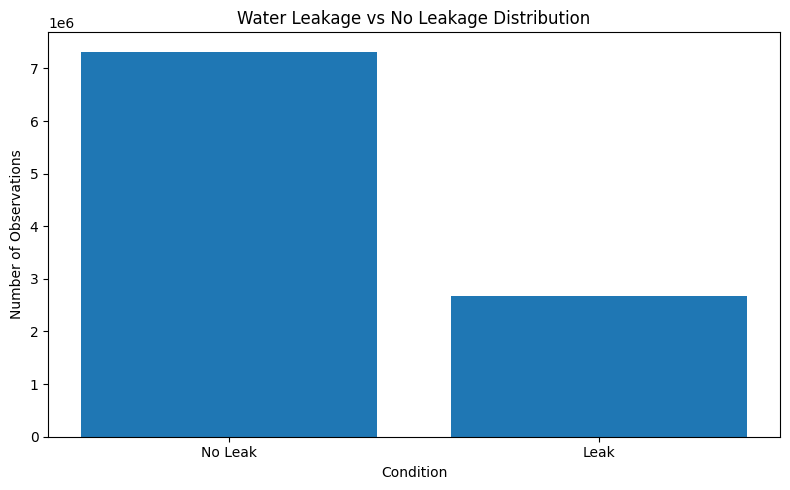

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    distribution["Condition"],
    distribution["Count"]
)

plt.title("Water Leakage vs No Leakage Distribution")
plt.xlabel("Condition")
plt.ylabel("Number of Observations")

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs/figures/leak_distribution.png",
    dpi=300
)

plt.show()

Analysis Pressure Distribution

In [16]:
eda_sample = df.sample(
    n=min(1000, len(df)),
    random_state=42
)

pressure_sample = pd.DataFrame({
    "Pressure": eda_sample[pressure_columns].to_numpy().ravel(),
    "Leak Status": eda_sample[leak_columns].to_numpy().ravel()
})

pressure_sample["Leak Status"] = (
    pressure_sample["Leak Status"]
    .map({0: "No Leak", 1: "Leak"})
)

display(pressure_sample.head())

,Pressure,Leak Status
0,49.494101,No Leak
1,51.254182,No Leak
2,46.733661,No Leak
3,40.888491,No Leak
4,49.047912,No Leak


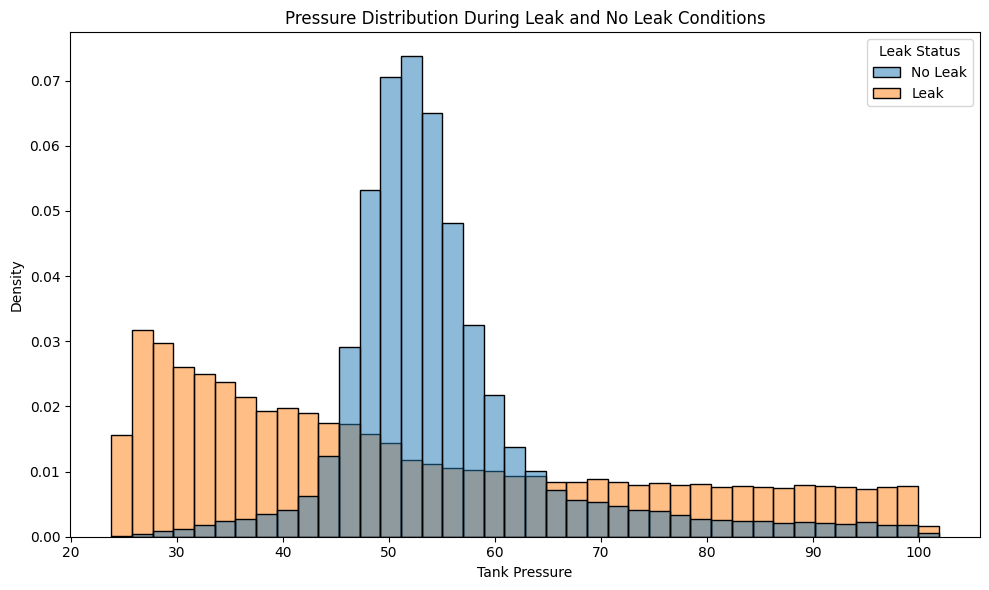

In [17]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=pressure_sample,
    x="Pressure",
    hue="Leak Status",
    bins=40,
    stat="density",
    common_norm=False,
    alpha=0.5
)

plt.title("Pressure Distribution During Leak and No Leak Conditions")
plt.xlabel("Tank Pressure")
plt.ylabel("Density")

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs/figures/pressure_distribution.png",
    dpi=300
)

plt.show()

Analyse leakage across individual tanks

In [18]:
tank_leak_rates = (
    df[leak_columns].mean() * 100
).sort_values(ascending=False)

print("Top 10 Tanks with Highest Leakage Percentage:")

display(
    tank_leak_rates.head(10).to_frame(
        "Leak Percentage"
    )
)

Top 10 Tanks with Highest Leakage Percentage:


,Leak Percentage
Tank88 Leak,37.979
Tank50 Leak,36.613
Tank68 Leak,36.541
Tank96 Leak,34.700
Tank18 Leak,34.650
Tank5 Leak,33.920
Tank10 Leak,33.620
Tank74 Leak,33.571
Tank38 Leak,33.065
Tank67 Leak,32.719


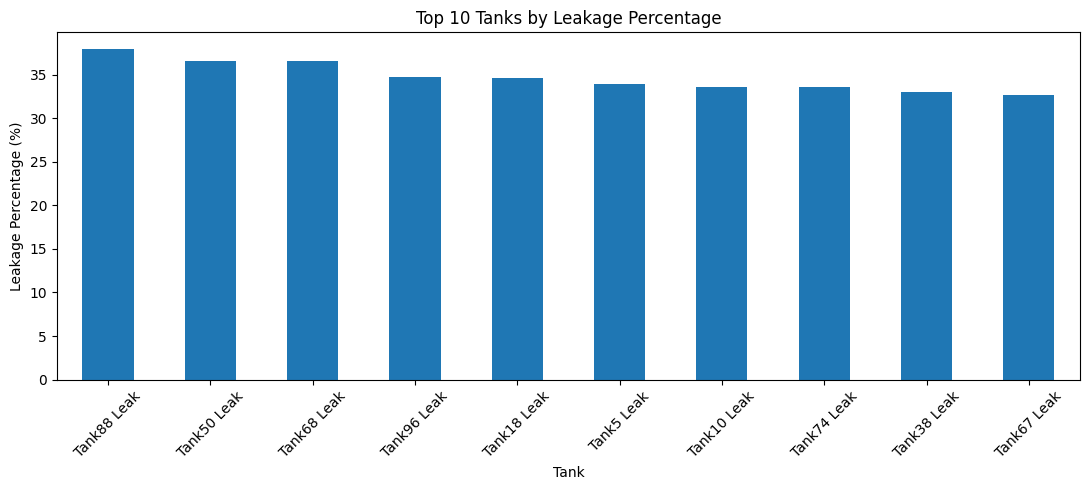

In [19]:
plt.figure(figsize=(11, 5))

tank_leak_rates.head(10).plot(
    kind="bar"
)

plt.title("Top 10 Tanks by Leakage Percentage")
plt.xlabel("Tank")
plt.ylabel("Leakage Percentage (%)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs/figures/tank_leak_comparison.png",
    dpi=300
)

plt.show()

Save EDA results

In [20]:
eda_summary = {
    "dataset_rows": int(df.shape[0]),
    "dataset_columns": int(df.shape[1]),
    "missing_values": int(df.isnull().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "leak_observations": int(leak_count),
    "no_leak_observations": int(no_leak_count),
    "leak_percentage": float(
        leak_count / (leak_count + no_leak_count) * 100
    ),
    "no_leak_percentage": float(
        no_leak_count / (leak_count + no_leak_count) * 100
    )
}

with open(
    PROJECT_DIR / "outputs/metrics/eda_summary.json",
    "w"
) as f:
    json.dump(eda_summary, f, indent=4)

print("EDA results saved successfully!")

EDA results saved successfully!


Temporal Analysis

In [21]:
window_size = 10000

temporal_results = []

for start in range(0, len(df), window_size):

    block = df.iloc[start:start + window_size]

    leak_data = block[leak_columns].to_numpy()
    pressure_data = block[pressure_columns].to_numpy()
    refill_data = block[refill_columns].to_numpy()

    total_observations = leak_data.size

    leak_percentage = (
        np.sum(leak_data) / total_observations
    ) * 100

    temporal_results.append({

        "Start Time": block["Time"].iloc[0],
        "End Time": block["Time"].iloc[-1],

        "Leak Percentage": leak_percentage,

        "Average Pressure": np.mean(pressure_data),

        "Refill Percentage": np.mean(refill_data) * 100

    })

temporal_df = pd.DataFrame(temporal_results)

display(temporal_df)

,Start Time,End Time,Leak Percentage,Average Pressure,Refill Percentage
0,0.0,9999.0,27.8747,54.928177,6.2785
1,10000.0,19999.0,27.5002,53.934001,6.1266
2,20000.0,29999.0,25.4382,53.763396,5.7282
3,30000.0,39999.0,29.4211,53.750506,6.5502
4,40000.0,49999.0,27.0250,54.130253,6.0599
5,50000.0,59999.0,26.7241,54.644965,5.9653
6,60000.0,69999.0,26.2212,54.620088,5.8689
7,70000.0,79999.0,26.3831,53.672067,5.8936
8,80000.0,89999.0,27.0526,53.949151,6.0550
9,90000.0,99999.0,24.3723,55.235986,5.4518


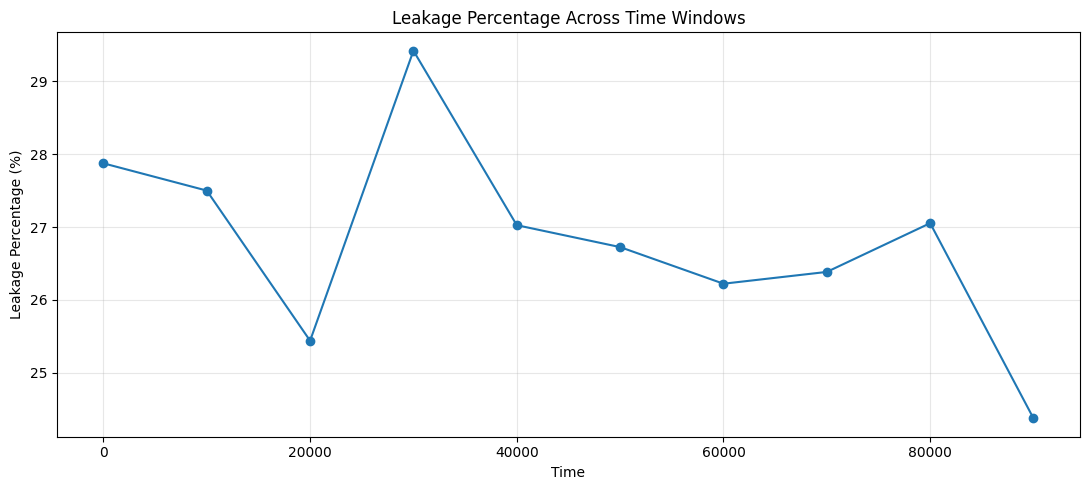

In [22]:
plt.figure(figsize=(11, 5))

plt.plot(
    temporal_df["Start Time"],
    temporal_df["Leak Percentage"],
    marker="o"
)

plt.title("Leakage Percentage Across Time Windows")
plt.xlabel("Time")
plt.ylabel("Leakage Percentage (%)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs/figures/temporal_leakage.png",
    dpi=300
)

plt.show()

In [23]:
temporal_df.to_csv(
    PROJECT_DIR / "outputs/metrics/temporal_analysis.csv",
    index=False
)

print("Temporal analysis saved successfully!")

Temporal analysis saved successfully!


Define the chronological split

In [24]:
# Verify chronological ordering

assert df["Time"].is_monotonic_increasing
assert df["Time"].is_unique

# Define split boundaries

TRAIN_END = 70000
VALIDATION_END = 85000

# Split by timestamp

train_df = df[df["Time"] < TRAIN_END].copy()

validation_df = df[
    (df["Time"] >= TRAIN_END) &
    (df["Time"] < VALIDATION_END)
].copy()

test_df = df[
    df["Time"] >= VALIDATION_END
].copy()

print("CHRONOLOGICAL DATA SPLITTING")

print("\nTraining:", train_df.shape)
print("Validation:", validation_df.shape)
print("Testing:", test_df.shape)

print("\nTraining time:",
      train_df["Time"].min(),
      "-",
      train_df["Time"].max())

print("Validation time:",
      validation_df["Time"].min(),
      "-",
      validation_df["Time"].max())

print("Testing time:",
      test_df["Time"].min(),
      "-",
      test_df["Time"].max())

CHRONOLOGICAL DATA SPLITTING

Training: (70000, 301)
Validation: (15000, 301)
Testing: (15000, 301)

Training time: 0.0 - 69999.0
Validation time: 70000.0 - 84999.0
Testing time: 85000.0 - 99999.0


Feature engineering

In [25]:
# Convert sensor measurements into NumPy arrays

pressure_matrix = df[pressure_columns].to_numpy(
    dtype=np.float32
)

refill_matrix = df[refill_columns].to_numpy(
    dtype=np.uint8
)

leak_matrix = df[leak_columns].to_numpy(
    dtype=np.uint8
)

time_array = df["Time"].to_numpy(
    dtype=np.int32
)

# Calculate pressure change for each tank

pressure_change_matrix = np.zeros_like(
    pressure_matrix
)

pressure_change_matrix[1:] = (
    pressure_matrix[1:] -
    pressure_matrix[:-1]
)

print("Feature engineering completed!")

print("Pressure shape:", pressure_matrix.shape)

print("Pressure change shape:",
      pressure_change_matrix.shape)

print("Refill shape:", refill_matrix.shape)

print("Leak shape:", leak_matrix.shape)

Feature engineering completed!
Pressure shape: (100000, 100)
Pressure change shape: (100000, 100)
Refill shape: (100000, 100)
Leak shape: (100000, 100)


Convert the dataset into long format

In [27]:
tank_ids = np.arange(100, dtype=np.uint8)

def create_long_dataset(start, end):

    number_of_rows = end - start

    long_data = pd.DataFrame({

        "Time": np.repeat(
            time_array[start:end],
            100
        ),

        "Tank_ID": np.tile(
            tank_ids,
            number_of_rows
        ),

        "Pressure": pressure_matrix[
            start:end
        ].reshape(-1),

        "Pressure_Change": pressure_change_matrix[
            start:end
        ].reshape(-1),

        "Refill": refill_matrix[
            start:end
        ].reshape(-1),

        "Leak": leak_matrix[
            start:end
        ].reshape(-1)

    })

    return long_data

Create training, validation and testing datasets

In [28]:
train_full = create_long_dataset(
    0, 70000
)

validation_full = create_long_dataset(
    70000, 85000
)

test_full = create_long_dataset(
    85000, 100000
)

print("LONG FORMAT DATASETS CREATED")

print("\nTraining:", train_full.shape)
print("Validation:", validation_full.shape)
print("Testing:", test_full.shape)

print("\nTotal observations:",
      len(train_full) +
      len(validation_full) +
      len(test_full))

display(train_full.head())

LONG FORMAT DATASETS CREATED

Training: (7000000, 6)
Validation: (1500000, 6)
Testing: (1500000, 6)

Total observations: 10000000


,Time,Tank_ID,Pressure,Pressure_Change,Refill,Leak
0,0,0,76.832291,0.0,0,0
1,0,1,57.371132,0.0,0,0
2,0,2,32.943855,0.0,0,0
3,0,3,59.739594,0.0,0,0
4,0,4,24.310362,0.0,1,1


Stratified sampling

In [29]:
def stratified_sample(data, n_samples, random_state=42):

    if n_samples > len(data):
        raise ValueError("Sample size exceeds dataset size.")

    labels = data["Leak"].to_numpy()

    positive_indices = np.flatnonzero(labels == 1)
    negative_indices = np.flatnonzero(labels == 0)

    positive_count = round(
        n_samples * len(positive_indices) / len(data)
    )

    negative_count = n_samples - positive_count

    rng = np.random.default_rng(random_state)

    selected_positive = rng.choice(
        positive_indices,
        size=positive_count,
        replace=False
    )

    selected_negative = rng.choice(
        negative_indices,
        size=negative_count,
        replace=False
    )

    selected_indices = np.concatenate([
        selected_positive,
        selected_negative
    ])

    rng.shuffle(selected_indices)

    return data.iloc[
        selected_indices
    ].reset_index(drop=True)

In [30]:
train_sample = stratified_sample(
    train_full,
    30000,
    random_state=42
)

validation_sample = stratified_sample(
    validation_full,
    10000,
    random_state=42
)

test_sample = stratified_sample(
    test_full,
    10000,
    random_state=42
)

print("SAMPLING COMPLETED")

print("Training:", train_sample.shape)
print("Validation:", validation_sample.shape)
print("Testing:", test_sample.shape)

SAMPLING COMPLETED
Training: (30000, 6)
Validation: (10000, 6)
Testing: (10000, 6)


Validate class distribution

In [31]:
def evaluate_distribution(name, data):

    total = len(data)

    no_leak = (data["Leak"] == 0).sum()

    leak = (data["Leak"] == 1).sum()

    print(f"\n{name}")

    print("Total:", total)

    print("No Leak:", no_leak)

    print("Leak:", leak)

    print("Leak Percentage:",
          round((leak / total) * 100, 2), "%")


evaluate_distribution("TRAINING", train_sample)

evaluate_distribution("VALIDATION", validation_sample)

evaluate_distribution("TESTING", test_sample)


TRAINING
Total: 30000
No Leak: 21848
Leak: 8152
Leak Percentage: 27.17 %

VALIDATION
Total: 10000
No Leak: 7342
Leak: 2658
Leak Percentage: 26.58 %

TESTING
Total: 10000
No Leak: 7471
Leak: 2529
Leak Percentage: 25.29 %


Define model input features

In [32]:
FEATURE_COLUMNS = [
    "Pressure",
    "Pressure_Change",
    "Refill"
]

TARGET_COLUMN = "Leak"

X_train = train_sample[FEATURE_COLUMNS].copy()
y_train = train_sample[TARGET_COLUMN].copy()

X_validation = validation_sample[FEATURE_COLUMNS].copy()
y_validation = validation_sample[TARGET_COLUMN].copy()

X_test = test_sample[FEATURE_COLUMNS].copy()
y_test = test_sample[TARGET_COLUMN].copy()

print("FEATURES AND TARGET PREPARED")

print("\nTraining features:", X_train.shape)
print("Validation features:", X_validation.shape)
print("Testing features:", X_test.shape)

print("\nFeature names:", FEATURE_COLUMNS)

FEATURES AND TARGET PREPARED

Training features: (30000, 3)
Validation features: (10000, 3)
Testing features: (10000, 3)

Feature names: ['Pressure', 'Pressure_Change', 'Refill']


Data quality verification

In [33]:
print("MISSING VALUE CHECK")

print("Training:", X_train.isnull().sum().sum())

print("Validation:", X_validation.isnull().sum().sum())

print("Testing:", X_test.isnull().sum().sum())


print("\nCLASS LABEL VALIDATION")

print("Training labels:", y_train.unique())

print("Validation labels:", y_validation.unique())

print("Testing labels:", y_test.unique())


print("\nFEATURE SUMMARY")

display(X_train.describe())

MISSING VALUE CHECK
Training: 0
Validation: 0
Testing: 0

CLASS LABEL VALIDATION
Training labels: [0 1]
Validation labels: [0 1]
Testing labels: [1 0]

FEATURE SUMMARY


,Pressure,Pressure_Change,Refill
count,30000.000000,30000.000000,30000.000000
mean,54.298122,-0.002695,0.060000
std,14.405523,0.671813,0.237491
min,6.322126,-2.732706,0.000000
25%,47.662273,-0.459166,0.000000
50%,52.462395,-0.012682,0.000000
75%,58.545316,0.442773,0.000000
max,101.175629,2.701752,1.000000


Save processed datasets

In [34]:
processed_dir = PROJECT_DIR / "data/processed"

train_sample.to_csv(
    processed_dir / "train_sample.csv",
    index=False
)

validation_sample.to_csv(
    processed_dir / "validation_sample.csv",
    index=False
)

test_sample.to_csv(
    processed_dir / "test_sample.csv",
    index=False
)

print("Processed datasets saved successfully!")

Processed datasets saved successfully!


In [35]:
split_metadata = {

    "split_strategy": "Chronological",

    "training_period": "0-69999",

    "validation_period": "70000-84999",

    "testing_period": "85000-99999",

    "original_observations": 10000000,

    "training_sample_size": len(train_sample),

    "validation_sample_size": len(validation_sample),

    "testing_sample_size": len(test_sample),

    "features": FEATURE_COLUMNS,

    "target": TARGET_COLUMN,

    "sampling_strategy": "Stratified sampling",

    "random_state": 42,

    "feature_engineering": [
        "Pressure",
        "Pressure Change",
        "Refill"
    ]

}

with open(
    PROJECT_DIR / "documentation/split_metadata.json",
    "w"
) as f:

    json.dump(split_metadata, f, indent=4)

print("Split documentation saved successfully!")

Split documentation saved successfully!


In [37]:
# FINAL PHASE 3 VALIDATION

# Dataset sizes
assert len(train_sample) == 30000
assert len(validation_sample) == 10000
assert len(test_sample) == 10000

# Chronological separation
assert train_sample["Time"].max() < validation_sample["Time"].min()

assert validation_sample["Time"].max() < test_sample["Time"].min()

# Feature validation
assert list(X_train.columns) == FEATURE_COLUMNS

assert X_train.isnull().sum().sum() == 0
assert X_validation.isnull().sum().sum() == 0
assert X_test.isnull().sum().sum() == 0

# Target validation
assert set(y_train.unique()).issubset({0, 1})
assert set(y_validation.unique()).issubset({0, 1})
assert set(y_test.unique()).issubset({0, 1})

# Infinite value validation
assert np.isfinite(X_train.to_numpy()).all()
assert np.isfinite(X_validation.to_numpy()).all()
assert np.isfinite(X_test.to_numpy()).all()


print("Chronological splitting: PASSED")
print("Feature validation: PASSED")
print("Target validation: PASSED")
print("Missing value validation: PASSED")
print("Infinite value validation: PASSED")

Chronological splitting: PASSED
Feature validation: PASSED
Target validation: PASSED
Missing value validation: PASSED
Infinite value validation: PASSED


#Machine Learning Model Implementation

In [38]:
import joblib
import time

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report
)

print("Model implementation libraries imported successfully!")

Model implementation libraries imported successfully!


Define model configurations

In [39]:
MODEL_CONFIGS = {

    "Logistic Regression": {
        "C": 1.0,
        "max_iter": 2000,
        "class_weight": "balanced",
        "random_state": 42
    },

    "Decision Tree": {
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 2,
        "class_weight": "balanced",
        "random_state": 42
    },

    "Random Forest": {
        "n_estimators": 200,
        "max_features": "sqrt",
        "min_samples_leaf": 2,
        "class_weight": "balanced_subsample",
        "n_jobs": -1,
        "random_state": 42
    },

    "SVM": {
        "C": 1.0,
        "kernel": "rbf",
        "gamma": "scale",
        "class_weight": "balanced",
        "cache_size": 2000
    }

}

print("Model configurations defined successfully!")

Model configurations defined successfully!


Step 3. Create model pipelines

In [40]:
models = {

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            **MODEL_CONFIGS["Logistic Regression"]
        ))
    ]),

    "Decision Tree": Pipeline([
        ("scaler", "passthrough"),
        ("classifier", DecisionTreeClassifier(
            **MODEL_CONFIGS["Decision Tree"]
        ))
    ]),

    "Random Forest": Pipeline([
        ("scaler", "passthrough"),
        ("classifier", RandomForestClassifier(
            **MODEL_CONFIGS["Random Forest"]
        ))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(
            **MODEL_CONFIGS["SVM"]
        ))
    ])

}

print("All four model pipelines created successfully!")

All four model pipelines created successfully!


Step 4. Prepare model storage

In [41]:
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

fitted_models = {}

training_times = {}

print("Model storage directory:", MODEL_DIR)

Model storage directory: /content/Water_Leakage_Project/models


Step 5. Create a training function

In [43]:
def train_model(name):

    print(f"\nTraining {name}...")

    model = models[name]

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    elapsed_time = time.perf_counter() - start_time

    training_times[name] = elapsed_time

    fitted_models[name] = model

    model_filename = (
        name.lower().replace(" ", "_") + ".joblib"
    )

    joblib.dump(
        model,
        MODEL_DIR / model_filename
    )

    print(f"{name} trained successfully!")

    print(f"Training time: {elapsed_time:.2f} seconds")

    print(f"Model saved: {model_filename}")

Step 6. Train Logistic Regression

In [44]:
train_model("Logistic Regression")


Training Logistic Regression...
Logistic Regression trained successfully!
Training time: 0.06 seconds
Model saved: logistic_regression.joblib


Step 7. Train Decision Tree

In [45]:
train_model("Decision Tree")


Training Decision Tree...
Decision Tree trained successfully!
Training time: 0.40 seconds
Model saved: decision_tree.joblib


Step 8. Train Random Forest

In [46]:
train_model("Random Forest")


Training Random Forest...
Random Forest trained successfully!
Training time: 19.22 seconds
Model saved: random_forest.joblib


Step 9. Train Support Vector Machine

In [47]:
train_model("SVM")


Training SVM...
SVM trained successfully!
Training time: 48.95 seconds
Model saved: svm.joblib


Step 10. Record training configurations

In [48]:
training_metadata = {

    "project": "Water Leakage Detection Using Machine Learning",

    "training_samples": len(X_train),

    "validation_samples": len(X_validation),

    "testing_samples": len(X_test),

    "features": FEATURE_COLUMNS,

    "target": TARGET_COLUMN,

    "random_state": 42,

    "models": MODEL_CONFIGS,

    "training_times_seconds": training_times,

    "scikit_learn_version": sklearn.__version__

}

with open(
    PROJECT_DIR / "documentation/model_configurations.json",
    "w"
) as f:

    json.dump(training_metadata, f, indent=4)

print("Model configurations documented successfully!")

Model configurations documented successfully!


Step 11. Preliminary model evaluation

In [49]:
validation_results = []

prediction_times = {}

for name, model in fitted_models.items():

    print(f"Evaluating {name}...")

    start_time = time.perf_counter()

    y_pred = model.predict(X_validation)

    prediction_time = time.perf_counter() - start_time

    prediction_times[name] = prediction_time

    if hasattr(model, "predict_proba"):

        y_scores = model.predict_proba(
            X_validation
        )[:, 1]

    else:

        y_scores = model.decision_function(
            X_validation
        )

    validation_results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            y_validation, y_pred
        ),

        "Precision": precision_score(
            y_validation, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_validation, y_pred, zero_division=0
        ),

        "F1-Score": f1_score(
            y_validation, y_pred, zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_validation, y_scores
        ),

        "PR-AUC": average_precision_score(
            y_validation, y_scores
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_validation, y_pred
        ),

        "Training Time (s)": training_times[name],

        "Prediction Time (s)": prediction_time

    })

validation_results_df = pd.DataFrame(
    validation_results
)

display(
    validation_results_df.round(4)
)

Evaluating Logistic Regression...
Evaluating Decision Tree...
Evaluating Random Forest...
Evaluating SVM...


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Balanced Accuracy,Training Time (s),Prediction Time (s)
0,Logistic Regression,0.7316,0.4959,0.5873,0.5377,0.7173,0.6192,0.6856,0.0583,0.0087
1,Decision Tree,0.7875,0.5836,0.6998,0.6364,0.7823,0.5686,0.7595,0.4034,0.0096
2,Random Forest,0.8579,0.7495,0.6990,0.7234,0.8757,0.7903,0.8072,19.2164,1.3593
3,SVM,0.8593,0.7164,0.7792,0.7464,0.8811,0.7536,0.8337,48.9462,23.7342


In [50]:
validation_results_df.to_csv(
    PROJECT_DIR / "outputs/metrics/validation_results.csv",
    index=False
)

print("Validation results saved successfully!")

Validation results saved successfully!


Step 12. Create model comparison visualization

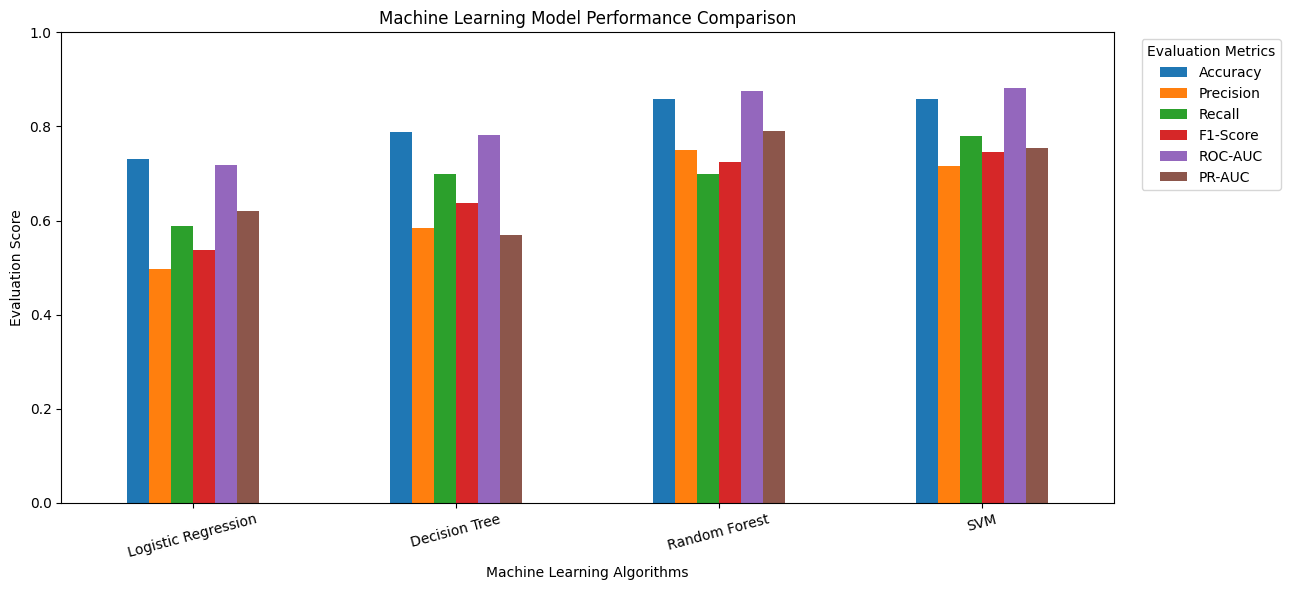

In [51]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

validation_results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Machine Learning Model Performance Comparison")

plt.xlabel("Machine Learning Algorithms")

plt.ylabel("Evaluation Score")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.legend(
    title="Evaluation Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs/figures/model_comparison_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Step 1: Generate confusion matrix statistics

In [52]:
confusion_results = []

for name, model in fitted_models.items():

    y_pred = model.predict(X_validation)

    tn, fp, fn, tp = confusion_matrix(
        y_validation,
        y_pred
    ).ravel()

    confusion_results.append({

        "Model": name,
        "True Negative": tn,
        "False Positive": fp,
        "False Negative": fn,
        "True Positive": tp

    })

confusion_results_df = pd.DataFrame(
    confusion_results
)

display(confusion_results_df)

,Model,True Negative,False Positive,False Negative,True Positive
0,Logistic Regression,5755,1587,1097,1561
1,Decision Tree,6015,1327,798,1860
2,Random Forest,6721,621,800,1858
3,SVM,6522,820,587,2071


Step 2: Visualize confusion matrices

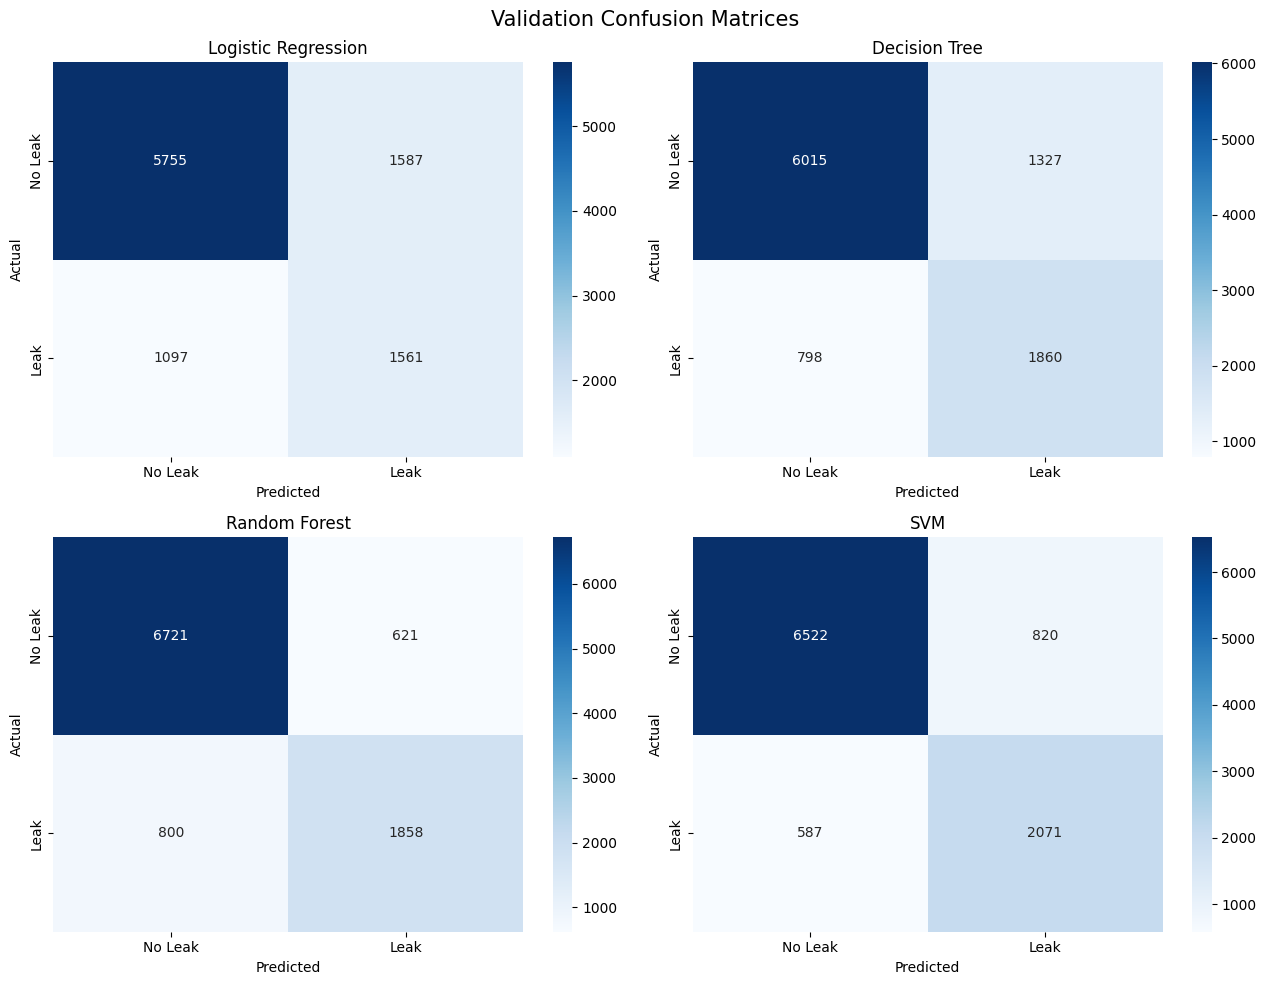

In [53]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

for (name, model), ax in zip(
    fitted_models.items(),
    axes.flatten()
):

    y_pred = model.predict(X_validation)

    cm = confusion_matrix(
        y_validation,
        y_pred
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Leak", "Leak"],
        yticklabels=["No Leak", "Leak"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle(
    "Validation Confusion Matrices",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs/figures/validation_confusion_matrices.png",
    dpi=300
)

plt.show()

Step 3: Save the results

In [54]:
confusion_results_df.to_csv(
    PROJECT_DIR / "outputs/metrics/validation_confusion_matrices.csv",
    index=False
)

print("Confusion matrix results saved successfully!")

Confusion matrix results saved successfully!


#Model Evaluation

Step 1. Check testing dataset

In [55]:
print("FINAL TEST DATASET")

print("Testing observations:", len(X_test))

print("\nClass distribution:")

print(y_test.value_counts())

print("\nLeak percentage:",
      round(y_test.mean() * 100, 2), "%")

print("\nFeature columns:", X_test.columns.tolist())

FINAL TEST DATASET
Testing observations: 10000

Class distribution:
Leak
0    7471
1    2529
Name: count, dtype: int64

Leak percentage: 25.29 %

Feature columns: ['Pressure', 'Pressure_Change', 'Refill']


Step 2. Evaluate all four models

In [56]:
test_results = []

test_predictions = {}

test_reports = {}

for name, model in fitted_models.items():

    print(f"\nEvaluating {name} on unseen test data...")

    start_time = time.perf_counter()

    y_pred = model.predict(X_test)

    prediction_time = time.perf_counter() - start_time

    test_predictions[name] = y_pred

    # Obtain continuous prediction scores

    if hasattr(model, "predict_proba"):

        y_scores = model.predict_proba(X_test)[:, 1]

    else:

        y_scores = model.decision_function(X_test)

    # Calculate confusion matrix

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0

    false_negative_rate = (
        fn / (fn + tp) if (fn + tp) else 0
    )

    test_results.append({

        "Model": name,

        "Accuracy": accuracy_score(y_test, y_pred),

        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),

        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test, y_scores
        ),

        "PR-AUC": average_precision_score(
            y_test, y_scores
        ),

        "Specificity": specificity,

        "False Negative Rate": false_negative_rate,

        "TN": tn,

        "FP": fp,

        "FN": fn,

        "TP": tp,

        "Prediction Time (s)": prediction_time

    })

    test_reports[name] = classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )

test_results_df = pd.DataFrame(test_results)

print("\nFINAL TEST RESULTS")

display(test_results_df.round(4))


Evaluating Logistic Regression on unseen test data...

Evaluating Decision Tree on unseen test data...

Evaluating Random Forest on unseen test data...

Evaluating SVM on unseen test data...

FINAL TEST RESULTS


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Specificity,False Negative Rate,TN,FP,FN,TP,Prediction Time (s)
0,Logistic Regression,0.7666,0.5345,0.5967,0.5639,0.7490,0.6472,0.8241,0.4033,6157,1314,1020,1509,0.0076
1,Decision Tree,0.7888,0.5664,0.7034,0.6275,0.7853,0.5622,0.8177,0.2966,6109,1362,750,1779,0.0071
2,Random Forest,0.8655,0.7541,0.6947,0.7232,0.8798,0.7928,0.9233,0.3053,6898,573,772,1757,0.6008
3,SVM,0.8593,0.7044,0.7643,0.7332,0.8873,0.7565,0.8914,0.2357,6660,811,596,1933,14.4576


Step 3. Save final evaluation results

In [57]:
test_results_df.to_csv(
    PROJECT_DIR / "outputs/metrics/final_test_results.csv",
    index=False
)

with open(
    PROJECT_DIR / "outputs/metrics/classification_reports.json",
    "w"
) as f:

    json.dump(test_reports, f, indent=4)

print("Final evaluation results saved successfully!")

Final evaluation results saved successfully!


Step 4. Generate final confusion matrices

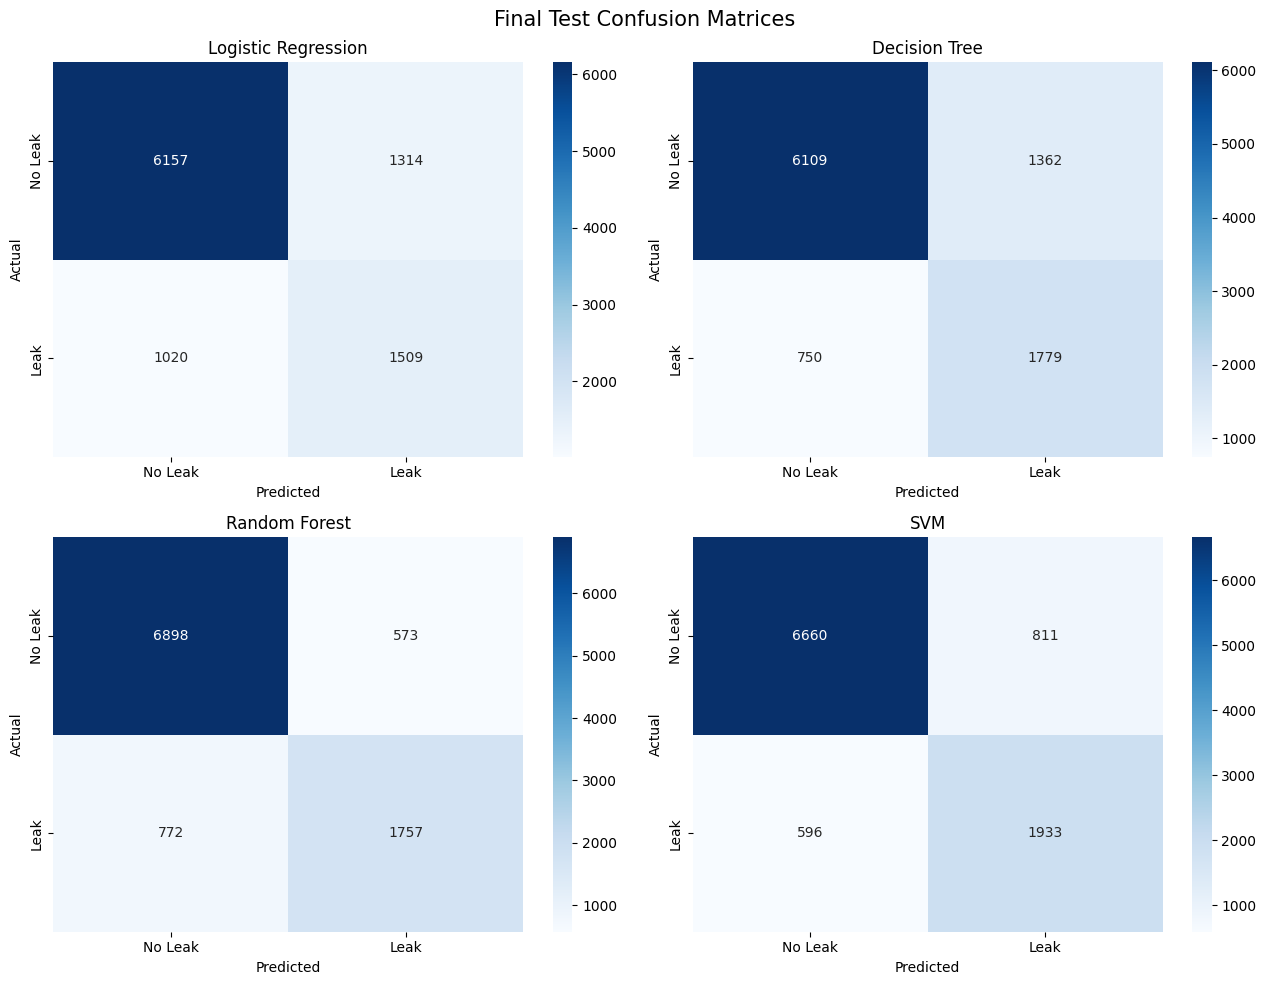

In [58]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

for (name, y_pred), ax in zip(
    test_predictions.items(),
    axes.flatten()
):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Leak", "Leak"],
        yticklabels=["No Leak", "Leak"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle(
    "Final Test Confusion Matrices",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs/figures/final_test_confusion_matrices.png",
    dpi=300
)

plt.show()

Step 5. Final performance comparison

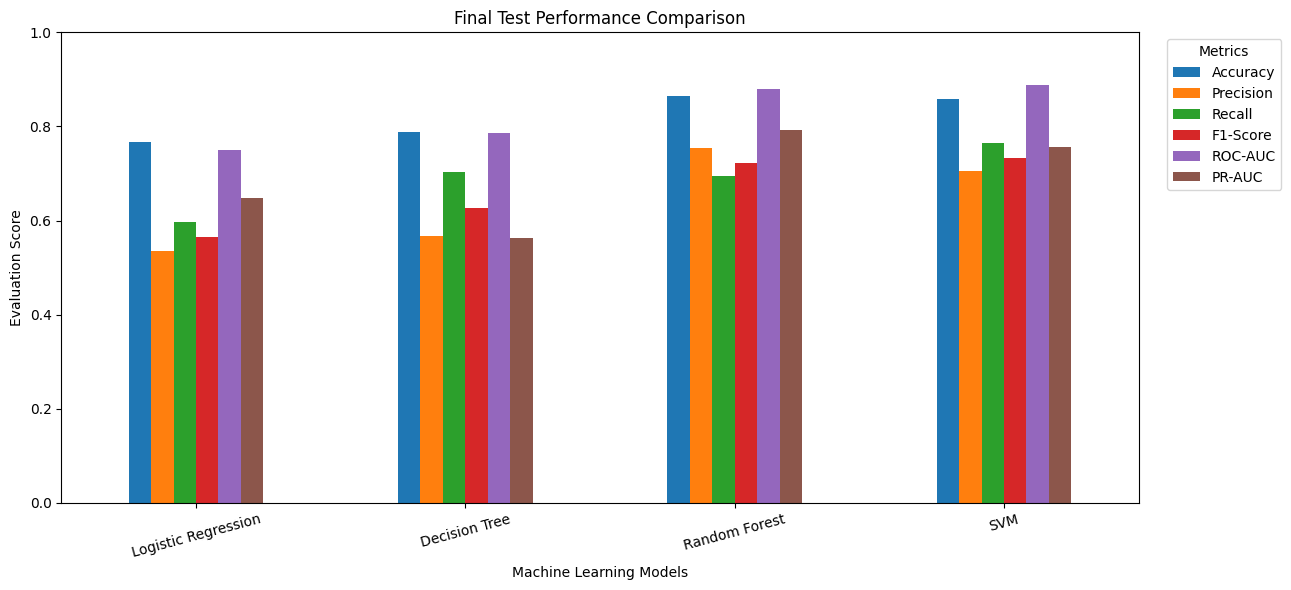

In [59]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

test_results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Final Test Performance Comparison")

plt.xlabel("Machine Learning Models")

plt.ylabel("Evaluation Score")

plt.ylim(0, 1)

plt.xticks(rotation=15)

plt.legend(
    title="Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs/figures/final_test_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Model Interpretation and Explainability

Step 1. Feature importance using permutation importance

In [60]:
from sklearn.inspection import permutation_importance

Step 2. Calculate feature importance

In [61]:
X_interpret = X_validation.sample(
    n=2000,
    random_state=42
)

y_interpret = y_validation.loc[
    X_interpret.index
]

importance_results = []

for name, model in fitted_models.items():

    print(f"Calculating importance for {name}...")

    result = permutation_importance(

        model,

        X_interpret,

        y_interpret,

        scoring="f1",

        n_repeats=5,

        random_state=42,

        n_jobs=1

    )

    for feature, mean_importance, std_importance in zip(

        FEATURE_COLUMNS,

        result.importances_mean,

        result.importances_std

    ):

        importance_results.append({

            "Model": name,

            "Feature": feature,

            "Importance": mean_importance,

            "Standard Deviation": std_importance

        })

importance_df = pd.DataFrame(
    importance_results
)

display(
    importance_df.round(5)
)

Calculating importance for Logistic Regression...
Calculating importance for Decision Tree...
Calculating importance for Random Forest...
Calculating importance for SVM...


,Model,Feature,Importance,Standard Deviation
0,Logistic Regression,Pressure,0.09328,0.01015
1,Logistic Regression,Pressure_Change,0.05420,0.00651
2,Logistic Regression,Refill,0.14418,0.00484
3,Decision Tree,Pressure,0.24193,0.00759
4,Decision Tree,Pressure_Change,0.02394,0.01257
5,Decision Tree,Refill,0.09820,0.00453
6,Random Forest,Pressure,0.31051,0.01461
7,Random Forest,Pressure_Change,0.01360,0.00704
8,Random Forest,Refill,0.12026,0.00436
9,SVM,Pressure,0.33952,0.01954


Step 3. Visualize feature importance

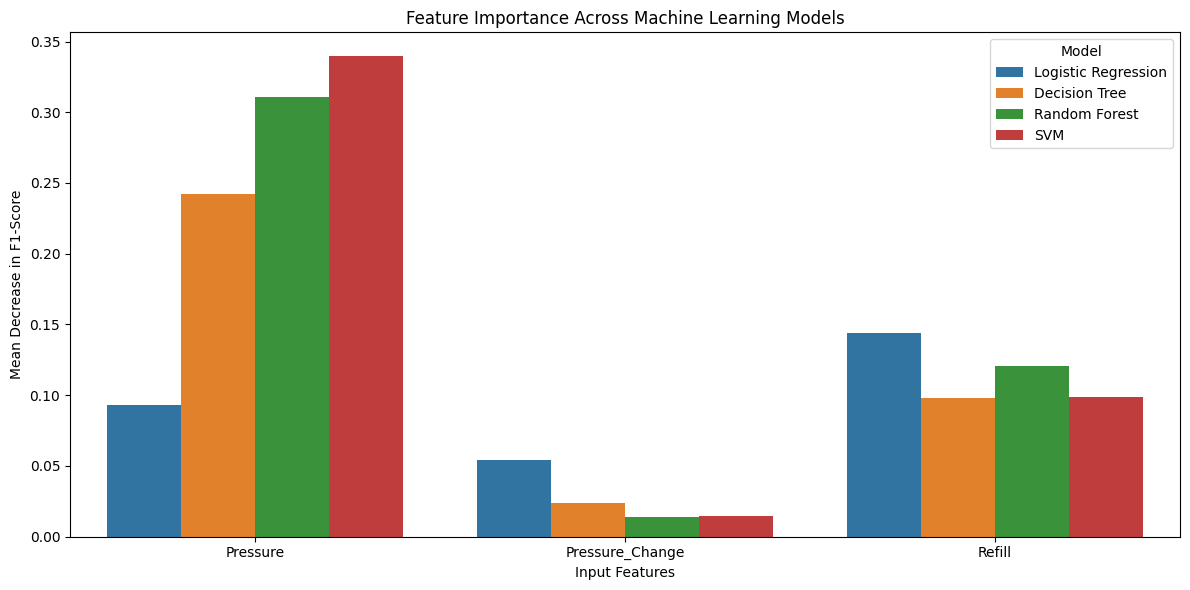

In [62]:
plt.figure(figsize=(12, 6))

sns.barplot(

    data=importance_df,

    x="Feature",

    y="Importance",

    hue="Model"

)

plt.title("Feature Importance Across Machine Learning Models")

plt.xlabel("Input Features")

plt.ylabel("Mean Decrease in F1-Score")

plt.tight_layout()

plt.savefig(

    PROJECT_DIR / "outputs/figures/feature_importance.png",

    dpi=300

)

plt.show()

Save the results:

In [63]:
importance_df.to_csv(

    PROJECT_DIR / "outputs/metrics/feature_importance.csv",

    index=False

)

print("Feature importance results saved!")

Feature importance results saved!


#Error Analysis

Step 1. Generate prediction errors

In [64]:
error_analysis_df = validation_sample[
    [
        "Time",
        "Tank_ID",
        "Pressure",
        "Pressure_Change",
        "Refill",
        "Leak"
    ]
].copy()

for name in ["Random Forest", "SVM"]:

    predictions = fitted_models[name].predict(
        X_validation
    )

    error_analysis_df[f"{name}_Prediction"] = predictions

    error_analysis_df[f"{name}_Error"] = np.select(

        [
            (error_analysis_df["Leak"] == 1) &
            (predictions == 0),

            (error_analysis_df["Leak"] == 0) &
            (predictions == 1)
        ],

        [
            "False Negative",
            "False Positive"
        ],

        default="Correct"
    )

print("Error analysis dataset created!")

display(error_analysis_df.head())

Error analysis dataset created!


,Time,Tank_ID,Pressure,Pressure_Change,Refill,Leak,Random Forest_Prediction,Random Forest_Error,SVM_Prediction,SVM_Error
0,79176,84,43.035912,0.290634,0,0,1,False Positive,0,Correct
1,72903,17,55.713459,0.205429,0,1,0,False Negative,0,False Negative
2,79503,57,41.640381,0.800747,0,0,1,False Positive,1,False Positive
3,73656,20,93.292206,0.236176,0,0,0,Correct,1,False Positive
4,76528,91,25.417589,-0.580511,0,1,1,Correct,1,Correct


Step 2. Compare prediction errors

In [65]:
error_summary = []

for name in ["Random Forest", "SVM"]:

    counts = error_analysis_df[
        f"{name}_Error"
    ].value_counts()

    for error_type in [
        "Correct",
        "False Positive",
        "False Negative"
    ]:

        error_summary.append({

            "Model": name,

            "Error Type": error_type,

            "Count": counts.get(error_type, 0)

        })

error_summary_df = pd.DataFrame(error_summary)

display(error_summary_df)

,Model,Error Type,Count
0,Random Forest,Correct,8579
1,Random Forest,False Positive,621
2,Random Forest,False Negative,800
3,SVM,Correct,8593
4,SVM,False Positive,820
5,SVM,False Negative,587


Step 3. Visualize errors

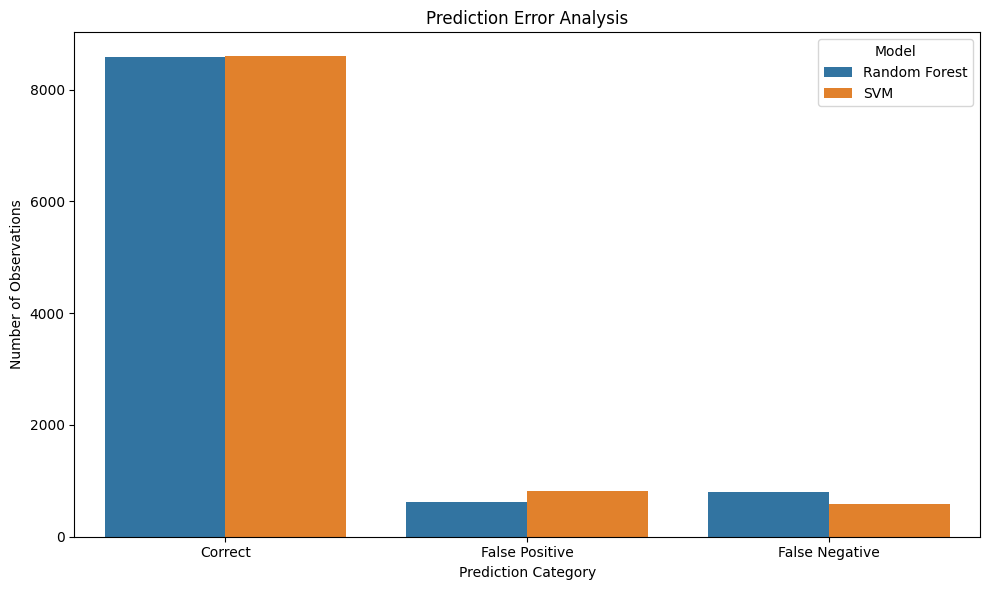

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(

    data=error_summary_df,

    x="Error Type",

    y="Count",

    hue="Model"

)

plt.title("Prediction Error Analysis")

plt.xlabel("Prediction Category")

plt.ylabel("Number of Observations")

plt.tight_layout()

plt.savefig(
    PROJECT_DIR / "outputs/figures/error_analysis.png",
    dpi=300
)

plt.show()

Step 4. Investigate missed leaks

In [67]:
for name in ["Random Forest", "SVM"]:

    print(f"\n{name} - MISSED LEAK ANALYSIS")

    missed_leaks = error_analysis_df[
        error_analysis_df[f"{name}_Error"] == "False Negative"
    ]

    print("Missed leaks:", len(missed_leaks))

    display(
        missed_leaks[
            ["Time", "Tank_ID", "Pressure",
             "Pressure_Change", "Refill"]
        ].describe()
    )


Random Forest - MISSED LEAK ANALYSIS
Missed leaks: 800


,Time,Tank_ID,Pressure,Pressure_Change,Refill
count,800.000000,800.000000,800.000000,800.000000,800.000000
mean,77490.445000,47.271250,58.687592,-0.127983,0.001250
std,4361.436805,28.140496,14.055955,0.641363,0.035355
min,70019.000000,0.000000,33.508522,-2.196999,0.000000
25%,73804.750000,24.000000,47.477571,-0.552724,0.000000
50%,77097.000000,45.000000,55.361202,-0.132473,0.000000
75%,81456.250000,69.000000,67.439341,0.286569,0.000000
max,84980.000000,99.000000,101.111565,2.399288,1.000000



SVM - MISSED LEAK ANALYSIS
Missed leaks: 587


,Time,Tank_ID,Pressure,Pressure_Change,Refill
count,587.000000,587.000000,587.000000,587.000000,587.0
mean,77407.930153,47.299830,53.991028,-0.055800,0.0
std,4357.668794,28.284248,8.431574,0.649166,0.0
min,70022.000000,0.000000,41.768982,-2.160397,0.0
25%,73775.000000,23.000000,47.041496,-0.493538,0.0
50%,76969.000000,46.000000,52.399929,-0.048412,0.0
75%,81200.500000,69.000000,59.210720,0.393917,0.0
max,84980.000000,99.000000,95.474258,1.847115,0.0


#Deployment Architecture and Model Monitoring

Step 1. Create deployment documentation

In [68]:
deployment_architecture = {

    "project": "Water Leakage Detection Using Machine Learning",

    "deployment_status": "Proposed - Not deployed on physical hardware",

    "selected_model": "SVM",

    "model_file": "models/svm.joblib",

    "input_features": [
        "Pressure",
        "Pressure_Change",
        "Refill"
    ],

    "workflow": [

        "Water tank sensors",

        "Data collection",

        "Data validation",

        "Feature engineering",

        "Trained SVM model",

        "Leak prediction",

        "Alert generation",

        "Monitoring dashboard",

        "Historical logging"

    ],

    "prediction_classes": {

        "0": "No Leak",

        "1": "Leak"

    }

}

with open(
    PROJECT_DIR / "documentation/deployment_architecture.json",
    "w"
) as f:

    json.dump(
        deployment_architecture,
        f,
        indent=4
    )

print("Deployment architecture documented successfully!")

Deployment architecture documented successfully!


Step 2. Create the prediction function

In [69]:
# Initialize monitoring variables

previous_pressure = {}

monitoring_records = []


def predict_water_leak(
    timestamp,
    tank_id,
    pressure,
    refill
):

    # Validate sensor input

    if not 0 <= int(tank_id) < 100:
        raise ValueError("Invalid tank ID.")

    if not np.isfinite(pressure):
        raise ValueError("Invalid pressure reading.")

    if refill not in (0, 1, 0.0, 1.0):
        raise ValueError("Refill must be 0 or 1.")

    tank_id = int(tank_id)

    pressure = float(pressure)

    refill = int(refill)

    # Calculate pressure change

    if tank_id in previous_pressure:

        pressure_change = (
            pressure - previous_pressure[tank_id]
        )

    else:

        pressure_change = 0.0

    previous_pressure[tank_id] = pressure

    # Prepare model input

    input_data = pd.DataFrame([{

        "Pressure": pressure,

        "Pressure_Change": pressure_change,

        "Refill": refill

    }])

    # Generate prediction

    start = time.perf_counter()

    prediction = fitted_models["SVM"].predict(
        input_data
    )[0]

    decision_score = fitted_models["SVM"].decision_function(
        input_data
    )[0]

    inference_time = (
        time.perf_counter() - start
    ) * 1000

    # Generate alert

    status = (
        "POTENTIAL LEAK DETECTED"
        if prediction == 1
        else "NORMAL"
    )

    result = {

        "Time": timestamp,

        "Tank_ID": tank_id,

        "Pressure": pressure,

        "Pressure_Change": pressure_change,

        "Refill": refill,

        "Prediction": int(prediction),

        "Status": status,

        "Decision_Score": float(decision_score),

        "Inference_Time_ms": inference_time

    }

    monitoring_records.append(result)

    return result

Step 3. Test the inference system

In [70]:
simulation_readings = [

    (100001, 0, 55.0, 0),

    (100002, 0, 52.0, 0),

    (100003, 0, 45.0, 0),

    (100004, 1, 60.0, 1),

    (100005, 1, 59.0, 0)

]

for reading in simulation_readings:

    result = predict_water_leak(*reading)

    print("\nPrediction:", result)


Prediction: {'Time': 100001, 'Tank_ID': 0, 'Pressure': 55.0, 'Pressure_Change': 0.0, 'Refill': 0, 'Prediction': 0, 'Status': 'NORMAL', 'Decision_Score': -1.3181427617735495, 'Inference_Time_ms': 37.56353000017043}

Prediction: {'Time': 100002, 'Tank_ID': 0, 'Pressure': 52.0, 'Pressure_Change': -3.0, 'Refill': 0, 'Prediction': 1, 'Status': 'POTENTIAL LEAK DETECTED', 'Decision_Score': 0.40332340317861654, 'Inference_Time_ms': 21.25495600012073}

Prediction: {'Time': 100003, 'Tank_ID': 0, 'Pressure': 45.0, 'Pressure_Change': -7.0, 'Refill': 0, 'Prediction': 1, 'Status': 'POTENTIAL LEAK DETECTED', 'Decision_Score': 0.5990070502491839, 'Inference_Time_ms': 14.04306499989616}

Prediction: {'Time': 100004, 'Tank_ID': 1, 'Pressure': 60.0, 'Pressure_Change': 0.0, 'Refill': 1, 'Prediction': 1, 'Status': 'POTENTIAL LEAK DETECTED', 'Decision_Score': 1.0000388255258876, 'Inference_Time_ms': 18.173228000250674}

Prediction: {'Time': 100005, 'Tank_ID': 1, 'Pressure': 59.0, 'Pressure_Change': -1.0, '

Step 4. Create monitoring logs

In [71]:
monitoring_df = pd.DataFrame(
    monitoring_records
)

monitoring_df.to_csv(

    PROJECT_DIR / "outputs/metrics/monitoring_logs.csv",

    index=False

)

display(monitoring_df)

print("Monitoring logs saved successfully!")

,Time,Tank_ID,Pressure,Pressure_Change,Refill,Prediction,Status,Decision_Score,Inference_Time_ms
0,100001,0,55.0,0.0,0,0,NORMAL,-1.318143,37.563530
1,100002,0,52.0,-3.0,0,1,POTENTIAL LEAK DETECTED,0.403323,21.254956
2,100003,0,45.0,-7.0,0,1,POTENTIAL LEAK DETECTED,0.599007,14.043065
3,100004,1,60.0,0.0,1,1,POTENTIAL LEAK DETECTED,1.000039,18.173228
4,100005,1,59.0,-1.0,0,0,NORMAL,-0.749259,8.280712


Monitoring logs saved successfully!


7.3 Model Monitoring Procedures
Step 5. Create monitoring documentation

In [72]:
monitoring_procedures = {

    "monitoring_frequency": "Continuous during operation",

    "performance_metrics": [

        "Accuracy",

        "Precision",

        "Recall",

        "F1-Score",

        "False Negative Rate"

    ],

    "data_quality_checks": [

        "Missing sensor readings",

        "Invalid pressure values",

        "Invalid refill indicators",

        "Duplicate or out-of-order timestamps"

    ],

    "drift_monitoring": [

        "Pressure distribution changes",

        "Pressure change distribution",

        "Refill frequency changes",

        "Prediction distribution changes"

    ],

    "latency_monitoring": [

        "Average inference time",

        "95th percentile inference time"

    ],

    "maintenance_actions": [

        "Investigate excessive false alarms",

        "Inspect missed leakage events",

        "Verify sensor calibration",

        "Review data drift",

        "Retrain when performance degradation is confirmed"

    ],

    "ground_truth_source": "Verified maintenance inspection records"

}

with open(
    PROJECT_DIR / "documentation/monitoring_procedures.json",
    "w"
) as f:

    json.dump(
        monitoring_procedures,
        f,
        indent=4
    )

print("Monitoring procedures documented successfully!")

Monitoring procedures documented successfully!


7.4 Monitor inference performance

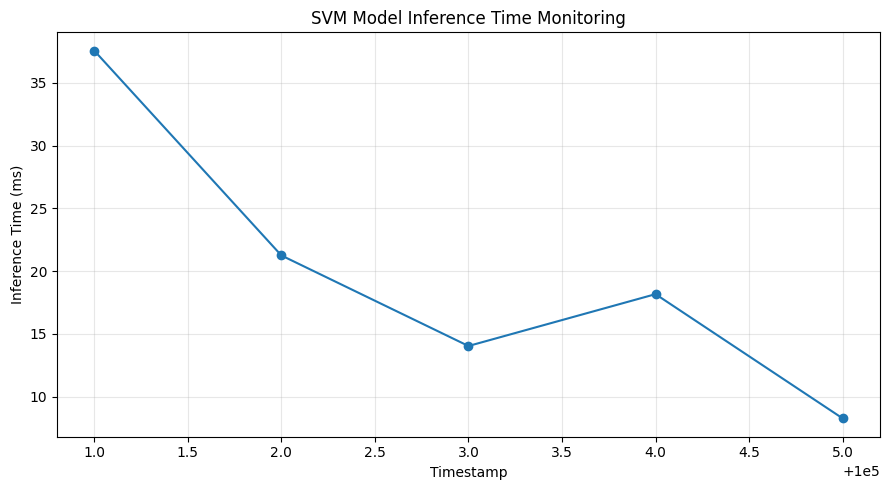

In [73]:
plt.figure(figsize=(9, 5))

plt.plot(

    monitoring_df["Time"],

    monitoring_df["Inference_Time_ms"],

    marker="o"

)

plt.title("SVM Model Inference Time Monitoring")

plt.xlabel("Timestamp")

plt.ylabel("Inference Time (ms)")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(

    PROJECT_DIR / "outputs/figures/inference_monitoring.png",

    dpi=300

)

plt.show()

Monitoring documentation

In [74]:
monitoring_procedures = {

    "monitoring_frequency": "Continuous during operation",

    "performance_metrics": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "False Negative Rate"
    ],

    "data_quality_checks": [
        "Missing sensor readings",
        "Invalid pressure values",
        "Invalid refill indicators",
        "Duplicate or out-of-order timestamps"
    ],

    "drift_monitoring": [
        "Pressure distribution changes",
        "Pressure change distribution",
        "Refill frequency changes",
        "Prediction distribution changes"
    ],

    "latency_monitoring": [
        "Average inference time",
        "95th percentile inference time"
    ],

    "maintenance_actions": [
        "Investigate excessive false alarms",
        "Inspect missed leakage events",
        "Verify sensor calibration",
        "Review data drift",
        "Retrain when performance degradation is confirmed"
    ],

    "ground_truth_source": "Verified maintenance inspection records",

    "deployment_status": "Proposed architecture with simulated inference"

}

with open(
    PROJECT_DIR / "documentation/monitoring_procedures.json",
    "w"
) as f:

    json.dump(monitoring_procedures, f, indent=4)

print("Monitoring procedures documented successfully!")

Monitoring procedures documented successfully!


#Create README.md
This will be the main documentation page of GitHub repository.

In [75]:
from textwrap import dedent

def markdown_table(dataframe):

    headers = list(dataframe.columns)

    rows = dataframe.astype(str).values.tolist()

    output = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]

    for row in rows:
        output.append(
            "| " + " | ".join(row) + " |"
        )

    return "\n".join(output)


results_table = test_results_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC"
    ]
].round(4)

results_markdown = markdown_table(results_table)

readme = f"""
# Water Leakage Detection Using Machine Learning

## Overview

This project develops a machine learning-based water leakage
detection system using pressure and refill measurements from
a simulated network of 100 connected water tanks.

Four classification algorithms are implemented and evaluated
to identify potential leakage conditions.

## Objectives

- Analyse water tank sensor measurements.
- Perform exploratory data analysis.
- Develop meaningful sensor-based features.
- Implement four classification algorithms.
- Evaluate and compare predictive performance.
- Investigate model errors and feature importance.
- Document a proposed deployment architecture.
- Establish model monitoring procedures.

## Technology Stack

| Component | Technology |
|---|---|
| Programming | Python |
| Environment | Google Colab |
| Data Processing | Pandas, NumPy |
| Visualization | Matplotlib, Seaborn |
| Machine Learning | Scikit-learn |
| Model Storage | Joblib |
| Version Control | Git and GitHub |

## Dataset

**Source:** {DATASET_URL}

**Repository commit:**

`{dataset_commit}`

The repository contains 14 CSV files. This experiment uses
the 12 measurement CSV files.

Original dataset dimensions:

- 100,000 timestamps
- 301 columns
- 100 tank pressure measurements
- 100 refill indicators
- 100 leakage indicators

The dataset contains 10 million individual tank-time observations.

## Exploratory Data Analysis

Important findings:

- Missing values: 0
- Duplicate rows: 0
- Leakage observations: 26.80%
- Normal observations: 73.20%
- Average pressure: 54.26
- Pressure change was examined over sequential timestamps.

## Feature Engineering

Three features are used:

1. Pressure
2. Pressure Change
3. Refill

The target variable is Leak:

- 0 = No Leak
- 1 = Leak

## Data Splitting

Chronological splitting was used.

| Dataset | Time Range | Sample Size |
|---|---|---:|
| Training | 0–69,999 | 30,000 |
| Validation | 70,000–84,999 | 10,000 |
| Testing | 85,000–99,999 | 10,000 |

Stratified sampling was performed independently within each
chronological period.

## Machine Learning Algorithms

- Logistic Regression
- Decision Tree
- Random Forest
- Support Vector Machine

## Final Test Results

{results_markdown}

## Model Selection

SVM is the preferred model when recall and F1-score are
the primary priorities.

Random Forest is a strong alternative when precision,
accuracy, PR-AUC and prediction efficiency are important.

## Explainability

Permutation importance was used to investigate the
contribution of Pressure, Pressure Change and Refill.

Pressure showed the greatest importance for SVM,
Random Forest and Decision Tree.

## Deployment

A proposed architecture includes:

Sensors → Data Collection → Preprocessing →
ML Prediction → Alert Generation → Monitoring.

A simulated inference function was implemented.

**Physical sensor deployment has not been implemented.**

## Monitoring

The proposed monitoring procedures cover:

- Prediction quality
- False alarms
- Missed leakage events
- Data quality
- Data drift
- Prediction latency

## Reproducibility

Dataset version, file checksums, software versions,
model configurations and dataset splitting details
are maintained in the documentation directory.

## Limitations

- Only three input features are used.
- Training uses a sampled subset of the observations.
- Performance is evaluated on a sampled future time period.
- Physical sensor deployment is not implemented.
- Hyperparameter optimization has not been exhaustive.
- Real-world performance requires validation using actual sensor data.

## Project Status

Machine learning implementation and experimental evaluation
completed. Deployment architecture and monitoring are documented
as proposed functionality.

## License

Specify the dataset and project license before redistribution.
"""

(PROJECT_DIR / "README.md").write_text(
    dedent(readme).strip(),
    encoding="utf-8"
)

print("README.md created successfully!")

README.md created successfully!


#Create Model Card
A model card documents the selected model, its intended use and its limitations.

In [76]:
svm_result = test_results_df[
    test_results_df["Model"] == "SVM"
].iloc[0]

svm_importance = importance_df[
    importance_df["Model"] == "SVM"
][["Feature", "Importance"]]

model_card = f"""
# Model Card — Support Vector Machine

## Model Information

Model: Support Vector Machine (SVM)

Algorithm: Support Vector Classification

Kernel: RBF

C: 1.0

Gamma: scale

Class Weight: balanced

Random State: Not explicitly set for SVC.

## Intended Purpose

Identify potential water leakage conditions from
water tank pressure, pressure change and refill measurements.

## Input Features

- Pressure
- Pressure Change
- Refill

## Output

0 — No Leak

1 — Leak

## Final Test Performance

| Metric | Result |
|---|---:|
| Accuracy | {svm_result['Accuracy']:.4f} |
| Precision | {svm_result['Precision']:.4f} |
| Recall | {svm_result['Recall']:.4f} |
| F1-Score | {svm_result['F1-Score']:.4f} |
| ROC-AUC | {svm_result['ROC-AUC']:.4f} |
| PR-AUC | {svm_result['PR-AUC']:.4f} |

## Explainability

Permutation importance was used to investigate
the contribution of each input feature.

{markdown_table(svm_importance.round(5))}

## Limitations

- The model uses only three input features.
- Predictions are based on the selected dataset.
- Real-world sensor performance remains unverified.
- Prediction scores are decision-function values,
  not calibrated probabilities.
- The current implementation has not been deployed
  on physical water tank hardware.

## Deployment Status

A simulated inference implementation exists.
Production deployment has not been performed.
"""

(PROJECT_DIR / "documentation/MODEL_CARD.md").write_text(
    dedent(model_card).strip(),
    encoding="utf-8"
)

print("Model card created successfully!")

Model card created successfully!


#Create Data Dictionary

In [77]:
data_dictionary = """
# Data Dictionary

| Feature | Data Type | Description |
|---|---|---|
| Time | Integer | Sequential timestamp index |
| Tank_ID | Integer | Identifier of one of the 100 tanks |
| Pressure | Float | Current tank pressure reading |
| Pressure_Change | Float | Difference between current and previous pressure |
| Refill | Binary | 1 indicates refill; 0 indicates no refill |
| Leak | Binary | 1 indicates leakage; 0 indicates no leakage |

## Target Variable

Leak is the binary classification target.

## Feature Engineering

Pressure Change is calculated as:

Pressure_Change(t) = Pressure(t) - Pressure(t-1)

The first available observation for each tank
uses zero as its initial pressure-change value.

## Model Input Features

Pressure, Pressure_Change and Refill.

Time and Tank_ID are retained for tracking
but excluded from the current model inputs.
"""

(PROJECT_DIR / "documentation/DATA_DICTIONARY.md").write_text(
    dedent(data_dictionary).strip(),
    encoding="utf-8"
)

print("Data dictionary created successfully!")

Data dictionary created successfully!


#Create requirements.txt
We should record the actual installed software versions rather than using unpinned dependencies

In [78]:
requirements = f"""
numpy=={np.__version__}
pandas=={pd.__version__}
scikit-learn=={sklearn.__version__}
matplotlib=={plt.matplotlib.__version__}
seaborn=={sns.__version__}
joblib=={joblib.__version__}
"""

(PROJECT_DIR / "requirements.txt").write_text(
    dedent(requirements).strip() + "\n",
    encoding="utf-8"
)

print("requirements.txt created successfully!")
print(requirements)

requirements.txt created successfully!

numpy==2.4.6
pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
joblib==1.6.0



Create assumptions and limitations document

In [79]:
assumptions_limitations = """
# Assumptions and Limitations

## Assumptions

1. Dataset labels are treated as the ground truth.
2. Pressure and refill measurements contain useful
   information for identifying water leakage.
3. Historical pressure observations are available
   for calculating pressure change.
4. The dataset is suitable for an initial experimental
   machine learning investigation.

## Limitations

1. Only three model input features are used.
2. Models are trained using a sampled subset.
3. No actual physical sensor network is connected.
4. The deployment workflow is proposed.
5. The inference demonstration uses simulated measurements.
6. Hyperparameter tuning has not been exhaustive.
7. Inter-tank relationships are not explicitly included
   in the current feature set.
8. Performance on real-world water infrastructure
   has not been established.
9. Permutation importance does not establish causality.
10. The prediction threshold has not been optimized
    for operational costs.

## Future Improvements

- Include tank connectivity information.
- Investigate additional time-series features.
- Perform systematic hyperparameter optimization.
- Evaluate alternative classification algorithms.
- Test on actual water distribution sensor data.
- Implement a real-time sensor integration system.
- Introduce automated drift detection.
"""

(PROJECT_DIR / "documentation/ASSUMPTIONS_AND_LIMITATIONS.md").write_text(
    dedent(assumptions_limitations).strip(),
    encoding="utf-8"
)

print("Assumptions and limitations documented!")

Assumptions and limitations documented!


Create Git version-control files

In [80]:
gitignore = """
__pycache__/
.ipynb_checkpoints/
*.pyc
.env
.DS_Store
*.log
data/raw/
"""

(PROJECT_DIR / ".gitignore").write_text(
    dedent(gitignore).strip() + "\n",
    encoding="utf-8"
)

70

In [81]:
changelog = """
# Changelog

## Version 1.0.0

- Initial project structure created.
- Dataset version and file checksums recorded.
- Exploratory data analysis completed.
- Temporal analysis performed.
- Chronological dataset splitting implemented.
- Pressure Change feature engineered.
- Four classification algorithms implemented.
- Model validation and final testing completed.
- Permutation feature importance calculated.
- Error analysis completed.
- Simulated inference implementation created.
- Deployment architecture documented.
- Monitoring procedures documented.
- Final model documentation prepared.
"""

(PROJECT_DIR / "CHANGELOG.md").write_text(
    dedent(changelog).strip(),
    encoding="utf-8"
)

print("Version-control documentation created!")

Version-control documentation created!


In [82]:
for root, dirs, files in os.walk(PROJECT_DIR):

    level = root.replace(str(PROJECT_DIR), "").count(os.sep)

    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

Water_Leakage_Project/
    .gitignore
    README.md
    CHANGELOG.md
    requirements.txt
    data/
        processed/
            validation_sample.csv
            test_sample.csv
            train_sample.csv
    models/
        random_forest.joblib
        decision_tree.joblib
        svm.joblib
        logistic_regression.joblib
    outputs/
        metrics/
            temporal_analysis.csv
            validation_results.csv
            eda_summary.json
            final_test_results.csv
            feature_importance.csv
            validation_confusion_matrices.csv
            classification_reports.json
            monitoring_logs.csv
        figures/
            feature_importance.png
            temporal_leakage.png
            final_test_confusion_matrices.png
            error_analysis.png
            leak_distribution.png
            validation_confusion_matrices.png
            model_comparison_validation.png
            final_test_comparison.png
            inference_moni

In [83]:
def to_markdown_table(data):

    data = data.copy()

    headers = list(data.columns)

    lines = [
        "| " + " | ".join(headers) + " |",
        "| " + " | ".join(["---"] * len(headers)) + " |"
    ]

    for row in data.astype(str).values.tolist():
        lines.append("| " + " | ".join(row) + " |")

    return "\n".join(lines)


# Prepare actual experimental tables

performance_table = to_markdown_table(
    test_results_df[
        [
            "Model", "Accuracy", "Precision",
            "Recall", "F1-Score", "ROC-AUC", "PR-AUC"
        ]
    ].round(4)
)

confusion_table = to_markdown_table(
    test_results_df[
        ["Model", "TN", "FP", "FN", "TP"]
    ]
)

importance_table = to_markdown_table(
    importance_df[
        ["Model", "Feature", "Importance", "Standard Deviation"]
    ].round(5)
)

temporal_table = to_markdown_table(
    temporal_df.round(3)
)

error_table = to_markdown_table(
    error_summary_df
)

training_table = to_markdown_table(
    pd.DataFrame([
        {
            "Model": name,
            "Training Time (seconds)": round(value, 4)
        }
        for name, value in training_times.items()
    ])
)

# Create report content

report = f"""
# WATER LEAKAGE DETECTION USING MACHINE LEARNING

## Abstract

This project presents a machine learning-based approach
for detecting water leakage in a network of 100 connected
water tanks.

The dataset contains 100,000 timestamps and 301 columns.
It provides pressure measurements, refill indicators and
binary leakage labels for each tank.

The project implements four classification algorithms:
Logistic Regression, Decision Tree, Random Forest and
Support Vector Machine (SVM).

A chronological training, validation and testing strategy
was adopted. Feature engineering was performed using
pressure, pressure change and refill indicators.

The final testing results showed that Random Forest
achieved the highest accuracy of 86.55%, while SVM
achieved the highest recall of 76.43% and F1-score
of 73.32%.

SVM was selected as the preferred model when detecting
a greater proportion of actual leakage observations
is the primary objective.

A proposed deployment architecture and monitoring
strategy were also documented. A simulated inference
function was implemented to demonstrate predictions
from sensor readings.

## 1. Introduction

Water leakage is an important problem in water storage
and distribution systems. Leakage can result in water
wastage, reduced system efficiency and pressure changes.

Manual inspection can be time-consuming.

Machine learning provides an approach for analysing
sensor readings and identifying patterns associated
with leakage conditions.

This project investigates the use of supervised
classification algorithms for detecting leakage in
a simulated network of connected water tanks.

## 2. Problem Statement

Develop a machine learning system that analyses water
tank pressure and refill measurements to classify
whether a tank is experiencing leakage.

The system should compare multiple classification
algorithms and evaluate their ability to identify
leakage observations.

## 3. Objectives

1. Obtain and understand the water tank dataset.
2. Perform exploratory data analysis.
3. Examine the temporal behaviour of leakage.
4. Prepare features for machine learning.
5. Implement four classification algorithms.
6. Evaluate model performance.
7. Investigate feature importance and prediction errors.
8. Document a proposed deployment architecture.
9. Establish monitoring and reproducibility procedures.

## 4. Literature Review

### 4.1 Khorasgani et al. (2019)

The researchers investigated fault detection and isolation
in industrial networks using Graph Convolutional Neural
Networks.

Their work includes a connected water tank network,
which is the source of the dataset used in this project.

Their research considers relationships between connected
network components. Our implementation instead uses
individual tank measurements as tabular classification
features.

### 4.2 Alves Coelho et al. (2020)

The authors presented a machine learning-based approach
for water leak detection using real-time sensor data.

Their research highlights the use of wireless sensor
networks and automated monitoring for identifying leaks.

### 4.3 Mashhadi et al. (2021)

The researchers investigated machine learning methods
for leak detection and localization in water distribution
systems.

Their study examined pressure and flow-related information
and compared supervised and unsupervised learning methods.

The research demonstrates the importance of selecting
appropriate algorithms for water distribution data.

### 4.4 Kammoun et al. (2022)

This study presents a comparative survey of artificial
intelligence applications for leak detection in water
distribution networks.

It provides an overview of different approaches to
leak detection and localization.

### 4.5 Shen and Cheng (2022)

The authors investigated tree-based machine learning
methods for pipeline leakage detection.

Their research addresses the challenges of identifying
leakage from practical pipeline signals.

### 4.6 Lee and Kim (2023)

The researchers investigated machine learning approaches
for detecting leakage using water pipeline vibration
sensor measurements.

Their work demonstrates the application of machine
learning to sensor-based leak detection.

## 5. Dataset Description

Dataset:
IndustrialNetwork/GraphDataset

Source:
https://github.com/IndustrialNetwork/GraphDataset

Dataset repository commit:

{dataset_commit}

The repository contains 14 CSV files, including:

- 12 measurement files.
- Tank location information.
- Tank connection matrix.

The 12 measurement files were combined.

Original dataset dimensions:

| Parameter | Value |
|---|---:|
| Rows | {df.shape[0]:,} |
| Columns | {df.shape[1]} |
| Pressure measurements | 100 |
| Refill indicators | 100 |
| Leak indicators | 100 |
| Total tank-time observations | 10,000,000 |

## 6. Exploratory Data Analysis

### 6.1 Data Quality

| Parameter | Result |
|---|---:|
| Missing values | {df.isnull().sum().sum()} |
| Duplicate rows | {df.duplicated().sum()} |
| Minimum timestamp | {df['Time'].min()} |
| Maximum timestamp | {df['Time'].max()} |
| Time ordering | Strictly increasing |

### 6.2 Sensor Statistics

| Sensor | Minimum | Maximum | Mean |
|---|---:|---:|---:|
| Pressure | {pressure_matrix.min():.4f} | {pressure_matrix.max():.4f} | {pressure_matrix.mean():.4f} |
| Refill | 0 | 1 | {refill_matrix.mean():.5f} |
| Leak | 0 | 1 | {leak_matrix.mean():.5f} |

The observed maximum pressure value exceeds 100 slightly.
This observation was retained and not automatically capped.

It should be investigated against the dataset's documented
sensor range before any production use.

### 6.3 Leakage Distribution

| Condition | Observations | Percentage |
|---|---:|---:|
| No Leak | {no_leak_count:,} | {distribution.iloc[0]['Percentage']:.2f}% |
| Leak | {leak_count:,} | {distribution.iloc[1]['Percentage']:.2f}% |

![Leak Distribution](../outputs/figures/leak_distribution.png)

### 6.4 Pressure Distribution

![Pressure Distribution](../outputs/figures/pressure_distribution.png)

### 6.5 Temporal Analysis

Leakage percentages were calculated across ten chronological
windows to investigate changes over time.

{temporal_table}

![Temporal Leakage](../outputs/figures/temporal_leakage.png)

## 7. Data Preprocessing

The dataset was divided chronologically.

| Partition | Timestamp Range | Sample Size |
|---|---|---:|
| Training | 0–69,999 | {len(train_sample):,} |
| Validation | 70,000–84,999 | {len(validation_sample):,} |
| Testing | 85,000–99,999 | {len(test_sample):,} |

Stratified sampling was applied independently to each
chronological partition.

The final modelling dataset contains 50,000 observations.

This approach avoids placing observations from the same
timestamp into different partitions.

## 8. Feature Engineering

Three input features were used:

| Feature | Description |
|---|---|
| Pressure | Current tank pressure |
| Pressure Change | Difference between current and previous pressure |
| Refill | Binary refill indicator |

Pressure change was calculated as:

Pressure Change = Current Pressure - Previous Pressure

The target variable is Leak:

- 0 = No Leak
- 1 = Leak

Time and Tank_ID were retained for analysis but were
not included as model input features.

## 9. Machine Learning Implementation

Four supervised classification algorithms were implemented.

### 9.1 Logistic Regression

Used as the baseline linear classification algorithm.

### 9.2 Decision Tree

Used to identify nonlinear relationships through
tree-based decision rules.

### 9.3 Random Forest

An ensemble model using 200 decision trees.

### 9.4 Support Vector Machine

An RBF-kernel SVM was implemented to identify
nonlinear classification boundaries.

StandardScaler was included in the Logistic Regression
and SVM pipelines.

Tree-based models were not scaled.

Class weighting was used to account for the
unequal class distribution.

### 9.5 Model Training Time

{training_table}

## 10. Final Model Evaluation

All four trained models were evaluated using the
previously held-out test sample of 10,000 observations.

### 10.1 Evaluation Metrics

Accuracy measures the proportion of correct predictions.

Precision measures how many predicted leaks were
actually leakage observations.

Recall measures how many actual leakage observations
were detected.

F1-score provides a balance between precision and recall.

ROC-AUC measures the ability to distinguish between
the two classes across classification thresholds.

PR-AUC summarizes the precision-recall relationship.

### 10.2 Final Test Results

{performance_table}

![Final Model Comparison](../outputs/figures/final_test_comparison.png)

## 11. Confusion Matrix Analysis

The final test confusion matrix counts are:

{confusion_table}

TN = True Negative

FP = False Positive

FN = False Negative

TP = True Positive

![Final Confusion Matrices](../outputs/figures/final_test_confusion_matrices.png)

Random Forest produced fewer false alarms than SVM.

SVM detected more actual leakage observations and
produced fewer missed leaks.

## 12. Comparative Analysis

Random Forest achieved the highest test accuracy
of 86.55%.

It also obtained the highest precision of 75.41%
and PR-AUC of 79.28%.

SVM achieved the highest recall of 76.43%,
F1-score of 73.32% and ROC-AUC of 88.73%.

SVM detected 1,933 actual leaks and missed 596.

Random Forest detected 1,757 actual leaks and
missed 772.

SVM is therefore preferred when reducing missed
leakage observations is the primary objective.

Random Forest remains an alternative when higher
precision, fewer false alarms and faster predictions
are important.

## 13. Model Explainability

Permutation importance was used to examine the
contribution of individual input features.

The analysis used 2,000 validation observations
and five permutation repeats.

{importance_table}

![Feature Importance](../outputs/figures/feature_importance.png)

Pressure had the greatest predictive importance
for SVM, Decision Tree and Random Forest.

Refill was the most important feature for
Logistic Regression.

Pressure Change had comparatively low importance
across the four models.

Permutation importance measures predictive contribution
and does not establish causality.

## 14. Error Analysis

Error analysis was performed using the validation
dataset.

{error_table}

![Error Analysis](../outputs/figures/error_analysis.png)

The results indicate a trade-off between false alarms
and missed leakage observations.

SVM produced fewer missed leaks than Random Forest,
while Random Forest generated fewer false alarms.

## 15. Proposed Deployment Architecture

The proposed architecture follows this workflow:

Water Tank Sensors

↓

Data Collection

↓

Data Validation

↓

Feature Engineering

↓

Trained SVM Model

↓

Leak Prediction

↓

Alert Generation

↓

Monitoring Dashboard

↓

Historical Data Logging

A simulated inference function was implemented
to demonstrate how pressure and refill observations
could be passed to the trained model.

Physical sensor integration and production deployment
have not been implemented.

## 16. Model Monitoring

The proposed monitoring procedures include:

- Accuracy, precision, recall and F1-score.
- False positive and false negative monitoring.
- Sensor data quality checks.
- Pressure and refill distribution monitoring.
- Data drift investigation.
- Inference latency measurement.
- Verified maintenance inspection records.

Retraining should be considered when verified
performance degradation is observed.

## 17. Assumptions and Limitations

### Assumptions

1. Dataset leakage labels are treated as ground truth.
2. Pressure and refill measurements provide useful
   information for leakage detection.
3. Previous pressure readings are available to calculate
   pressure change.
4. The dataset is suitable for an initial experimental study.

### Limitations

1. Only three input features were used.
2. Training was performed on a sampled subset.
3. The dataset is simulation-based.
4. The physical sensor system has not been deployed.
5. Hyperparameter tuning was not exhaustive.
6. Inter-tank relationships were not explicitly used
   as model features.
7. Real-world performance remains unverified.
8. Prediction thresholds have not been optimized
   using operational cost information.
9. Permutation importance does not establish causal
   relationships.

## 18. Future Scope

Future improvements may include:

- Adding inter-tank connectivity features.
- Investigating additional time-series features.
- Applying systematic hyperparameter optimization.
- Evaluating calibrated prediction probabilities.
- Testing with actual water distribution measurements.
- Developing a real-time monitoring interface.
- Integrating physical water tank sensors.
- Implementing automated drift detection.

## 19. Conclusion

This project investigated supervised machine learning
methods for detecting water leakage in a simulated
network of connected water tanks.

Four classification models were implemented and
evaluated using a chronological sampling strategy.

Random Forest achieved the highest accuracy,
while SVM achieved the highest recall and F1-score.

Considering that missed leakage events are particularly
important in this application, SVM was selected as
the preferred experimental model.

The project also included feature importance analysis,
error analysis, simulated inference, deployment
documentation and monitoring procedures.

The results demonstrate the potential of machine
learning for sensor-based water leakage detection.

However, further validation with real-world sensor
measurements is required before operational deployment.

## 20. References

1. Khorasgani, H., Hasanzadeh, A., Farahat, A. K., & Gupta, C. (2019).
Fault Detection and Isolation in Industrial Networks using
Graph Convolutional Neural Networks.
2019 IEEE International Conference on Prognostics and
Health Management, 1–7.
https://doi.org/10.1109/ICPHM.2019.8819403

2. Alves Coelho, J., Glória, A., & Sebastião, P. (2020).
Precise Water Leak Detection Using Machine Learning
and Real-Time Sensor Data.
IoT, 1(2), 474–493.
https://doi.org/10.3390/iot1020026

3. Mashhadi, N., Shahrour, I., Attoue, N., El Khattabi, J.,
& Aljer, A. (2021).
Use of Machine Learning for Leak Detection and Localization
in Water Distribution Systems.
Smart Cities, 4(4), 1293–1315.
https://doi.org/10.3390/smartcities4040069

4. Kammoun, M., Kammoun, A., & Abid, M. (2022).
Leak Detection Methods in Water Distribution Networks:
A Comparative Survey on Artificial Intelligence Applications.
Journal of Pipeline Systems Engineering and Practice,
13(3).
https://doi.org/10.1061/(ASCE)PS.1949-1204.0000646

5. Shen, Y., & Cheng, W. (2022).
A Tree-Based Machine Learning Method for Pipeline
Leakage Detection.
Water, 14(18), 2833.
https://doi.org/10.3390/w14182833

6. Lee, S., & Kim, B. (2023).
Machine Learning Model for Leak Detection Using Water
Pipeline Vibration Sensor.
Sensors, 23(21), 8935.
https://doi.org/10.3390/s23218935

## 21. Reproducibility Information

Dataset repository commit:
{dataset_commit}

Python:
{environment['python_version'].split()[0]}

Pandas: {pd.__version__}

NumPy: {np.__version__}

Scikit-learn: {sklearn.__version__}

Random seed used for sampling: 42

Dataset checksums are maintained in:
documentation/dataset_manifest.csv

Model configurations are maintained in:
documentation/model_configurations.json
"""

report_path = PROJECT_DIR / "reports/FINAL_PROJECT_REPORT.md"

report_path.write_text(
    report,
    encoding="utf-8"
)

print("FINAL PROJECT REPORT CREATED!")
print("Location:", report_path)
print("Report size:", report_path.stat().st_size, "bytes")

FINAL PROJECT REPORT CREATED!
Location: /content/Water_Leakage_Project/reports/FINAL_PROJECT_REPORT.md
Report size: 17263 bytes


In [84]:
from google.colab import files
import shutil

uploaded = files.upload()

notebook_folder = PROJECT_DIR / "notebooks"
notebook_folder.mkdir(parents=True, exist_ok=True)

for filename in uploaded:

    if filename.endswith(".ipynb"):

        destination = (
            notebook_folder /
            "Water_Leakage_Detection_Rebuild.ipynb"
        )

        shutil.copy2(filename, destination)

        print("Notebook saved successfully!")
        print("Location:", destination)
        print("Size:", round(destination.stat().st_size / 1024, 2), "KB")

Saving Water_Leakage_Detection_Rebuild.ipynb to Water_Leakage_Detection_Rebuild.ipynb
Notebook saved successfully!
Location: /content/Water_Leakage_Project/notebooks/Water_Leakage_Detection_Rebuild.ipynb
Size: 956.11 KB


In [85]:
notebook_path = (
    PROJECT_DIR /
    "notebooks/Water_Leakage_Detection_Rebuild.ipynb"
)

assert notebook_path.exists()

print("Notebook verification: PASSED")

Notebook verification: PASSED


In [86]:
report_path = (
    PROJECT_DIR /
    "reports/FINAL_PROJECT_REPORT.md"
)

print("Report exists:", report_path.exists())

if report_path.exists():
    print("Report size:",
          round(report_path.stat().st_size / 1024, 2),
          "KB")

Report exists: True
Report size: 16.86 KB


In [87]:
%pip -q install markdown xhtml2pdf pypdf

In [88]:
import markdown
import os
from xhtml2pdf import pisa
from pypdf import PdfReader

report_path = PROJECT_DIR / "reports/FINAL_PROJECT_REPORT.md"

pdf_path = PROJECT_DIR / "reports/FINAL_PROJECT_REPORT.pdf"

markdown_text = report_path.read_text(encoding="utf-8")

html_body = markdown.markdown(
    markdown_text,
    extensions=[
        "tables",
        "fenced_code",
        "sane_lists"
    ]
)

html_document = f"""
<!DOCTYPE html>
<html>
<head>
<meta charset="UTF-8">

<style>

@page {{
    size: A4;
    margin: 18mm 16mm;
}}

body {{
    font-family: Helvetica;
    font-size: 10pt;
    line-height: 1.5;
    color: #222;
}}

h1 {{
    font-size: 21pt;
    color: #17365D;
    border-bottom: 2px solid #17365D;
    padding-bottom: 8px;
}}

h2 {{
    font-size: 15pt;
    color: #1F4E79;
    margin-top: 22px;
}}

h3 {{
    font-size: 12pt;
    color: #365F91;
}}

table {{
    width: 100%;
    border-collapse: collapse;
    margin: 12px 0;
}}

th {{
    background-color: #17365D;
    color: white;
}}

td, th {{
    border: 1px solid #bbb;
    padding: 6px;
    font-size: 8.5pt;
}}

img {{
    max-width: 100%;
    height: auto;
}}

code {{
    font-size: 8pt;
}}

</style>
</head>

<body>
{html_body}
</body>
</html>
"""

base_dir = str(report_path.parent)

def resolve_images(uri, rel):

    if uri.startswith("http"):
        return uri

    resolved = os.path.abspath(
        os.path.join(base_dir, uri)
    )

    return resolved if os.path.exists(resolved) else uri


with open(pdf_path, "wb") as output_file:

    result = pisa.CreatePDF(
        html_document,
        dest=output_file,
        path=base_dir,
        link_callback=resolve_images
    )

if result.err:
    raise RuntimeError("PDF generation encountered errors.")

reader = PdfReader(str(pdf_path))

print("PDF GENERATED SUCCESSFULLY!")
print("Location:", pdf_path)
print("Pages:", len(reader.pages))
print("Size:", round(pdf_path.stat().st_size / 1024, 2), "KB")

'<p>↓</p>'


PDF GENERATED SUCCESSFULLY!
Location: /content/Water_Leakage_Project/reports/FINAL_PROJECT_REPORT.pdf
Pages: 14
Size: 1313.69 KB


In [89]:
from google.colab import files

files.download(str(pdf_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>